# PCB Inspection: live demo

Loads the **final system saved by the v6 run** (Cell 100) and inspects held-out VisA boards at any of the fifteen evaluated angles, with **no re-training**. The model code below is copied unchanged from `pcb_inspection.ipynb`; only the loading and the Gradio app are new.

If the Gradio link does not work, the last cell runs the same inspection without the app.

In [1]:
# W1 -- setup: Gradio, imports, determinism, device
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=False)
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["MPLBACKEND"] = "Agg"                      # figures are captured for the app, not shown inline
try:
    import os, glob, json, math, time, random, zipfile, pickle, shutil, warnings
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import numpy as np
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import pandas as pd
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import cv2
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import matplotlib.pyplot as plt
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import os as _os
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import torch
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import torch.nn as nn
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import torch.nn.functional as F
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import timm
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from sklearn.neighbors import NearestNeighbors
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from sklearn.metrics import roc_auc_score
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from tqdm.auto import tqdm
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import re, time, datetime, traceback, shutil
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from contextlib import contextmanager
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from sklearn.neighbors import NearestNeighbors as _SklearnNearestNeighbors
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import re
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from collections import defaultdict
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from collections import Counter
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import tarfile
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import urllib.request
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from sklearn.linear_model import LogisticRegression
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from sklearn.preprocessing import StandardScaler
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from sklearn.pipeline import make_pipeline
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from sklearn.model_selection import StratifiedGroupKFold
except Exception as _e:
    print('optional import skipped:', _e)
try:
    from sklearn.metrics import balanced_accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix
except Exception as _e:
    print('optional import skipped:', _e)
try:
    import gc
except Exception as _e:
    print('optional import skipped:', _e)
import io, contextlib, glob
from PIL import Image
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__, "| timm", timm.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


device: cuda | torch 2.11.0+cu130 | timm 1.0.30


In [2]:
# W2 -- find the saved final system in the attached v6 output
_hits = glob.glob("/kaggle/input/**/pcb_anomaly_artifacts/final_system/final_detectors.pkl", recursive=True)
if not _hits:
    raise FileNotFoundError("final_system not found: add the committed v6 notebook (IITJ FINAL PROJECT) as Input (Add Input -> Your Work -> Notebooks).")
FINAL_DIR = os.path.dirname(_hits[0])
ART_DIR = os.path.dirname(FINAL_DIR)
OUT_ROOT = os.path.dirname(ART_DIR)                    # root of the v6 run's /kaggle/working
print("final system :", FINAL_DIR)
print("files        :", sorted(os.listdir(FINAL_DIR)))
print(json.load(open(os.path.join(FINAL_DIR, "manifest.json")))["versions"])

final system : /kaggle/input/notebooks/naghulkrishna/iitj-final-project/pcb_anomaly_artifacts/final_system
files        : ['config.json', 'demo_images.json', 'final_detectors.pkl', 'golden_references.pkl', 'manifest.json', 'pixel_thresholds.json']
{'torch': '2.10.0+cu128', 'timm': '1.0.26', 'cv2': '4.13.0', 'numpy': '2.0.2', 'sklearn': '1.6.1', 'PIL': '11.3.0'}


In [3]:
# W3 -- model definitions, copied unchanged from pcb_thesis_final_v6.ipynb (function and class definitions only)
doc_section = lambda *a, **k: None
def log(msg, level="INFO"):
    print("[%s] %s" % (level, msg))
caption = lambda *a, **k: None

# ---- from v6 Cell 2

class CFG:
    CLASSES = ["pcb1", "pcb2", "pcb3", "pcb4"]

    # IMG_SIZE must be a multiple of 14 (DINOv2 ViT-S/14 patch size) AND reasonably
    # divisible by the CNN's stride-8 layer2 output for clean alignment. 336 satisfies both.
    IMG_SIZE = 336

    CNN_BACKBONE = "wide_resnet50_2"
    VIT_BACKBONE = "vit_small_patch14_dinov2.lvd142m"   # DINOv2 ViT-S/14, self-supervised pretrained
    NEIGHBORHOOD_POOL = 3                    # local-neighborhood aggregation kernel for the CNN branch (PatchCore trick)

    MAX_TRAIN_IMAGES_PER_CLASS = 150         # raised from 100: richer candidate pool for the coreset
    AUGS_PER_IMAGE = 5                       # invariance views per training image (0 = the Cell 15c ablation)

    CORESET_RATIO = 0.02                     # fraction of patch vectors kept in memory bank
    CORESET_MAX_POINTS_FOR_GREEDY = 20000    # cap for the greedy coreset pass (keeps it fast)
    MAX_BANK_SIZE = 5000                     # per-branch memory-bank cap. HONEST RECORD of this value: it was
                                              # raised from 2000 citing a 'PatchCore 159K-point vs 2000-point' comparison that
                                              # was WRONG -- Anomalib's default PatchCore bank is 15,359 points and the earlier
                                              # 'matched' variant really had ~193-482 points. Held-out AUROC did not measurably
                                              # change (0.841 -> 0.836), and a 482-point PatchCore beat this 5,000-point model,
                                              # so bank size is NOT this model's bottleneck. Kept at 5000 because GPU k-NN
                                              # (Cell 6b) makes it cheap. Hard cap on final memory-bank size, regardless of
                                              # CORESET_RATIO -- bank size drives THREE separate
                                              # costs that compound across this notebook's several
                                              # memory banks (main CNN/ViT + canonical CNN/ViT, x4
                                              # classes): the coreset greedy-selection loop (linear
                                              # in bank size), compute_bank_density's self-kNN
                                              # (QUADRATIC in bank size), and every single k-NN
                                              # query for the rest of the notebook's life (fit,
                                              # calibration, evaluation, every test_single_image
                                              # call).
                                              #
                                              # CUT from 8000 to 2000 after a real Kaggle run's
                                              # papermill cell timings showed Cell 9 (fit + calibrate)
                                              # alone taking 124 minutes -- with the quadratic density
                                              # step almost certainly the dominant cost at bank size
                                              # 8000 (an 8000x8000 self-kNN is 16x more expensive than
                                              # a 2000x2000 one). This is a real accuracy/speed
                                              # trade-off, not a free win -- a smaller coreset is a
                                              # less exhaustive reference set. Raise this back up if
                                              # you have compute budget to spare and want to test
                                              # whether it measurably improves AUROC; 2000 diverse
                                              # (greedy farthest-point-selected) points per bank is
                                              # still well within the range PatchCore's own ablations
                                              # show working reasonably well.

    KNN_K = 5                                # raised from 3 after the Cell 15b sweep on the CALIBRATION split
                                              # favored larger K for 3/4 classes (pcb3 preferred K=1). Held-out AUROC did not
                                              # measurably change -- report as a sensitivity result, not an improvement.
    TOPK_SCORE_FRAC = 0.03                   # raised from 0.01 on the same calibration-sweep evidence. Image
                                              # score = mean of the top X% most anomalous patches, NOT a single max (Cell 8)

    USE_DENSITY_REWEIGHT = True              # PatchCore-style local-density re-weighting (Cell 7/8):
                                              # a test patch matched to a memory-bank point sitting in a
                                              # DENSE/typical region gets its distance AMPLIFIED (more
                                              # suspicious); a match to a SPARSE/rare-but-legitimate
                                              # region gets DAMPENED -- reduces false positives from
                                              # naturally rare normal patterns (text labels, mounting
                                              # holes) without losing sensitivity to real defects
    DENSITY_K = 3                            # neighbors used to estimate each bank point's local density
    DENSITY_MAX_AMPLIFY = 8.0                # safety cap on how much a single sparse/dense match can
                                              # amplify a raw distance, in case of near-duplicate bank points
    THRESHOLD_PERCENTILE = 99.0              # fallback percentile if a calib split has no anomaly examples
    CALIBRATION_FRAC = 0.5                   # fraction of each class's labeled test images used to PICK
                                              # the threshold; the rest is held out for Cell 10's AUROC.
                                              #
                                              # Tried raising this to 0.65 to close the gap between the
                                              # calibration-set FPR target and actual held-out FPR (see
                                              # MAX_FALSE_POSITIVE_RATE below) -- REVERTED after a real
                                              # A/B comparison at matched settings showed no real payoff:
                                              # held-out FPR barely moved (15.9% -> 15.5%, noise-level)
                                              # while recall came out slightly WORSE (51.5% -> 46.4%) and
                                              # the smaller eval set gave noisier Cell 10 metrics for no
                                              # benefit. Combined with MAX_FALSE_POSITIVE_RATE's revert
                                              # below, three real runs now consistently show this
                                              # generalization gap doesn't respond to threshold-selection
                                              # hyperparameters -- it reflects genuine class separability
                                              # limits (AUROC ~0.68-0.90) and calibration-sample noise at
                                              # this scale (~100-130 images/class), not a methodology bug
                                              # fixable by tuning CFG constants further.

    TTA_CALIBRATION_MAX_IMAGES = None        # calibrate the TTA threshold on the FULL calibration split (was
                                              # capped at 50 for runtime; affordable now with GPU k-NN)

    REGION_PERCENTILE = 94.0                 # per-image percentile used to binarize the anomaly map
                                              # for region localization (Cell 11) -- lower than before
                                              # (was 97) to capture a fuller halo around each defect so
                                              # the merge step below has enough to consolidate into one
                                              # big region instead of several small hot-pixel fragments
    REGION_MERGE_FACTOR = 1.6                # circles within this many x (r1+r2) of each other get
                                              # merged into one bigger region -- see merge_close_regions
    MAX_REGIONS = 2                          # report at most 1-2 big regions per image, not many small ones

    MAX_FALSE_POSITIVE_RATE = 0.10           # the FINAL decision threshold (single-pass, TTA, and
                                              # canonical) is chosen to maximize recall SUBJECT TO this
                                              # false-positive-rate cap on the calibration set, instead
                                              # of pure F1 optimization. F1 treats false positives and
                                              # false negatives as equally costly and is tuned on an
                                              # artificially balanced 50/50 calibration set -- verified
                                              # in a real run that this can silently produce a threshold
                                              # with an unacceptable ~50% false-positive rate against a
                                              # realistic, mostly-normal deployment stream (rejecting
                                              # half of all genuinely good boards).
                                              #
                                              # REVERTED from 0.07 back to 0.10 -- a real run at 0.07
                                              # showed this lever backfiring: held-out FPR barely moved
                                              # (15.9%->12.7%) while held-out recall COLLAPSED
                                              # (51.5%->37.9%, and one class dropped to 25.7% recall --
                                              # missing 3 of every 4 real defects). The target-overshoot
                                              # ratio (held-out FPR / calibration target) also got WORSE,
                                              # not better (1.59x -> 1.81x): tightening this value is not
                                              # actually closing the calibration/held-out generalization
                                              # gap, it's just paying an ever-steeper recall cost while
                                              # still missing the target. That pattern -- a steep
                                              # recall-vs-FPR trade-off that doesn't improve with a
                                              # stricter target -- is a sign of a genuine separability
                                              # ceiling (AUROC ~0.68-0.90 here), not a threshold-tuning
                                              # problem. If you need a materially lower real-world FPR,
                                              # the effective lever is improving the underlying score
                                              # quality (CFG.MAX_TRAIN_IMAGES_PER_CLASS, CFG.AUGS_PER_IMAGE,
                                              # CFG.CORESET_RATIO), not squeezing this value further.

    # Orientation-aware canonical-alignment pathway (Cell 14) -- an OPTIONAL, additive
    # second pathway that estimates a board's true rotation and screens for defects that
    # are DEFINED by orientation (wrong polarity, tombstoning), which the main
    # rotation-INVARIANT pathway above is structurally blind to by design.
    BUILD_CANONICAL_PATHWAY = False          # Cell 14 only builds/calibrates this pathway if True.
                                              # DEFAULT OFF after a real Kaggle run's papermill timings
                                              # showed Cell 14 alone taking 47 minutes (20% of a 3h45m
                                              # total run) for a feature that is already off by default
                                              # at inference (test_single_image/inspect_pcb only use it
                                              # when you explicitly pass check_orientation=True). Most
                                              # deployments don't need wrong-polarity/tombstoning
                                              # detection specifically and can skip this cost entirely.
                                              # Set True (then re-run Cell 14) if you do want it --
                                              # check_orientation=True will otherwise just print a note
                                              # and skip gracefully, same as if the pathway were never
                                              # built for a class.
    CANONICAL_ANGLE_COARSE_STEP = 45         # degrees, initial coarse orientation search
    CANONICAL_ANGLE_FINE_STEP = 10           # degrees, refinement step size
    CANONICAL_ANGLE_FINE_RANGE = 30          # +/- degrees around the coarse best angle to refine

    EVAL_MAX_IMAGES_PER_CLASS = None         # FULL held-out eval split. Was 60, which silently compared our
                                              # model on 60 images/class against baselines on 100 -- not the same data. GPU
                                              # k-NN makes the full set cheap. Must stay None for the paired statistics.

    TTA_ANGLES = [0, 90, 180, 270]           # rotation test-time augmentation angles

    KAGGLE_INPUT = "/kaggle/input"
    WORK_DIR = "/kaggle/working"
    EXTRACT_DIR = "/kaggle/working"
    ARTIFACT_DIR = "/kaggle/working/pcb_anomaly_artifacts"

    # ---- Efficiency ----
    USE_GPU_KNN = True                       # exact GPU k-NN (Cell 6b), self-checked against sklearn; ~80% of
                                              # scoring time was CPU k-NN in a profiled run

    # ---- Statistics ----
    BOOTSTRAP_N = 2000                       # stratified paired-bootstrap replicates for every CI
    PAC_CONFIDENCE = 0.90                    # Cell 18's second operating point: held-out false alarms <= target
                                              # MAX_FALSE_POSITIVE_RATE with this probability (pac_threshold, Cell 7b)

    # ---- Ablations (Cell 15c) ----
    RUN_ABLATION = True                      # branch ablation (free) + no-augmentation refit (~10 min)

    # ---- Baselines (Cells 16-18) ----
    ANOMALIB_ROOT = "/kaggle/working/anomalib_data"
    RUN_BASELINES = True
    BASELINE_MODEL_NAMES = ["PatchCore", "PatchCore (matched bank)", "PaDiM", "EfficientAD",
                            "PatchCore (canonical pipeline)", "EfficientAD (canonical pipeline)",
                            "STFPM (canonical pipeline)", "Reverse Distillation (canonical pipeline)"]
                                              # "(canonical pipeline)" = trained, calibrated AND tested on canonicalized
                                              # boards, exactly like our canonical pipeline (Cell 15e) -- so a comparison of
                                              # DETECTORS is not confounded with a comparison of PIPELINES. A real run showed
                                              # test-only canonicalization left EfficientAD sensitive to reference-filled
                                              # border strips (scores rose with fill area in 23/24 groups). Drop the
                                              # EfficientAD variant to save ~40 min.
                                              # keep PatchCore FIRST: it is fast, so if raw-score mode is not
                                              # supported by the installed Anomalib this is discovered before
                                              # EfficientAD's long training (see Cell 17)
    EFFICIENTAD_EPOCHS = 20                  # already far below the paper's schedule; lowering it further would
                                              # handicap the strongest baseline -- remove EfficientAD instead
    ANOMALIB_PATCHES_PER_IMAGE = 1024        # Anomalib PatchCore patch grid per image (32x32 at its 256 px
                                              # input). Verified from a real log: ratio 0.1 on 150 images
                                              # selected 15,359 points = 1,024/image. Used to size the
                                              # matched-bank variant to exactly MAX_BANK_SIZE.
    BASELINE_RAW_SCORES = True               # disable Anomalib's min-max+clamp post-processing (clamping
                                              # creates ties that distort AUROC under distribution shift);
                                              # falls back automatically if unsupported

    # ---- Robustness benchmark (Cells 15d, 20) ----
    RUN_ROBUSTNESS = True
    ROBUSTNESS_CONDITIONS = ["identity", "rot90", "rot180", "rot15", "dark", "uneven_light", "crop"]
    ROBUSTNESS_MAX_IMAGES_PER_CLASS = 60     # class-balanced subset of the HELD-OUT eval split
    ROBUSTNESS_LONG_SIDE = 512               # every condition (incl. the identity control) re-saved at this size
    ROBUSTNESS_CROP_FRAC = 0.8               # centered crop keeps 80% of each side
    ROBUSTNESS_CROP_MIN_DEFECT_FRAC = 0.9    # anomalous images kept for 'crop' only if >=90% of the defect
                                              # (ground-truth mask) survives -- keeps labels truthful
    ROBUSTNESS_DIR = "/kaggle/working/robustness_sets"
    ROBUSTNESS_BASELINES = ["PatchCore", "EfficientAD", "PatchCore (canonical pipeline)", "EfficientAD (canonical pipeline)",
                            "STFPM (canonical pipeline)", "Reverse Distillation (canonical pipeline)"]
    BASELINE_EPOCHS = {"STFPM": 50, "Reverse Distillation": 50}   # trainable baselines besides EfficientAD (EFFICIENTAD_EPOCHS)   # strongest two; others skip the extra predictions
    ROBUSTNESS_INCLUDE_TTA = True            # TTA is our mode built for arbitrary angles -- test it under rotation
    ROBUSTNESS_CANONICALIZE = True           # ALSO score every condition after golden-reference canonicalization
                                              # (Cell 7c) -- the "+canon" columns of Part 3, for EVERY model
    CANON_ORB_FEATURES = 3000                # ~40% faster than 5000 with equal accuracy on synthetic boards
    CANON_MIN_INLIERS = 20                   # fewer RANSAC inliers -> registration declared failed (and counted)
    CANON_RATIO_TEST = 0.8                   # Lowe ratio test for ORB matches
    CANON_ILLUM_SIGMA_FRAC = 0.08            # illumination field = Gaussian low-pass at 8% of image size; defects
                                              # much smaller than that survive (verified on synthetic boards)
    CANON_ECC_SIZE = 256                     # resolution of the orientation check + sub-pixel ECC refinement (7c v2)
    CANON_PHOTOMETRIC_GATE = 0.15            # correct lighting ONLY if the median |log brightness ratio| to the
    CANON_GATE_PERCENTILE = 90               # FINAL BUILD bug fix: the gate tests this percentile of |log gain| over the board. It
                                             # used the MEDIAN, so shadows / glare covering < half the board never triggered a correction
    SATURATION_LEVEL = 250                   # FINAL BUILD over-exposure / glare gate: a pixel is clipped when ALL channels are >= this
    SATURATION_GATE_FRAC = 1.0               # DISABLED after run 30: the gate fired on 44.6% of NORMAL photos (VisA boards have
                                             # naturally clipped white areas) and cut clean AUROC 0.950 -> 0.872. 1.0 = never fires.
    SATURATION_DILATE_FRAC = 0.004           # margin around clipped pixels (fraction of the long side) also treated as unseen
    GLOBAL_BETA_GRID = (0.0, 0.5, 1.0)       # FINAL BUILD v4: global-evidence correction -- image score minus beta x the board's
                                             # MEDIAN patch score; beta chosen per class on calibration data only
    GLOBAL_BETA_MIN_GAIN = 0.005             # beta > 0 is adopted only if it raises calibration AUROC by at least this much
                                              # reference exceeds this (~16%); correctly-lit boards stay untouched
                                              # (ungated correction altered every image and hurt PatchCore under
                                              # uneven light in a real run)
    CANON_FEATHER_PX = 8                     # blend width where unseen regions are filled in from the reference

    # ---- Canonical pipeline for OUR model (Cell 15e) ----
    RUN_CANON_PIPELINE = True                # fit + calibrate our model ON canonicalized images (train/test
                                              # consistency). A real run showed canonicalizing only at TEST time
                                              # cut our model's clean AUROC 0.848 -> 0.694 while the baselines were
                                              # unaffected. No invariance augmentation: canonicalization replaces it.
    CANON_PIPELINE_DIR = "/kaggle/working/canonical_pipeline"
    CANON_REFERENCE_CANDIDATES = 30          # golden reference = the most TYPICAL of the first N training boards
                                              # (median brightness); the first image alone was atypically lit for
                                              # pcb4 in a real run (the lighting gate fired on 71% of its boards)
    DETERMINISTIC_BASELINES = True           # deterministic cuDNN kernels while training baselines. Seeds alone did not
                                              # make EfficientAD reproducible (identical seeds: pcb3 0.913 vs 0.842)
    SEED_STUDY_EXTRA_SEEDS = 2               # Cell 20c: re-train the 3 top systems with this many EXTRA seeds (~65 min
                                              # each, mostly EfficientAD); 0 skips. Claims then hold across training seeds.
    BOARD_ONLY = True                        # aligned systems score ONLY the board (not the background surface) and only
                                              # the part of the board that was in the photo
    BOARD_DEFECT_MAX_DIST = 0.15             # board mask grown LOCALLY to calibration defects within this fraction of the
                                              # long side of the board (convex hull) -- never a uniform margin
    CANON_RETRY_UPSCALE = 1.5                # failed alignment (e.g. a half-board photo): retry once on an upscaled copy
    BOARD_MASK_MODE = "auto"                 # "auto" = find the board on each class's reference (Cell 15d2 shows it);
                                              # "full" = treat the whole frame as board
    SEEN_DIR = "/kaggle/working/seen_masks"  # per-image "what the photo showed" masks of aligned images
    RUN_SWEEPS = True                        # Cell 20d: AUROC at every SWEEP_ANGLES and SWEEP_CROPS (~30 min)
    SWEEP_ANGLES = [0, 15, 30, 45, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360]   # degrees, counter-clockwise
    SWEEP_LIGHTS = ["bright x1.6", "dim x0.5", "very dim x0.3", "gamma 0.6", "gamma 1.6", "gradient left-right",
                    "gradient top-bottom", "vignette", "warm light", "cool light", "low contrast", "shadow band", "glare spot"]
    DISK_WARN_GB = 3.0                       # every section logs free disk space; below this it lists the largest folders
    DOC_FIG_DPI = 150                        # resolution of every saved thesis figure (thesis_outputs/figures)
    RUN_FINAL_ABLATION = True                # Cell D5 (~20 min): what each component of the final pipeline contributes
    PIXEL_NORMAL_QUANTILE = 0.90             # pixel highlight threshold = strongest pixel of 90% of CALIBRATION normal boards
    PIXEL_CALIB_IMAGES = 40                  # calibration normal boards per class used for that threshold
    PIXEL_NEG_SAMPLES = 4000                 # normal pixels sampled per board for the pixel-level AUROC
    DEMO_GOOD_PER_CLASS = 2                  # Cell 22b: random held-out NORMAL boards shown per class
    DEMO_BAD_PER_CLASS = 2                   # Cell 22b: random held-out DEFECTIVE boards shown per class
    SWEEP_CROPS = [0.9, 0.8, 0.7, 0.6, 0.5]  # fraction of each side kept in the photo (centred)
    SWEEP_HALVES = ["left", "right", "top", "bottom"]   # photos showing only HALF of the board
    SWEEP_IMAGES_PER_CLASS = 40              # held-out boards per class (half normal, half defective)
    RUN_AUG_STUDY = True                     # Cell 15e3: one repaired training copy per board, selected on calibration
                                              # shift sets; if selected, used by EVERY canonical-pipeline detector
    RUN_CANON_STUDY = True                   # Cell 15e2: final pre-registered letterbox x CLAHE study of the canonical
                                              # pipeline (~30 min); selection on calibration only
    RUN_IMPROVEMENT_STUDY = True             # Cell 15c2: pre-registered, calibration-selected model improvements
    DEPLOY_BASELINES = ["EfficientAD", "PatchCore", "PatchCore (canonical pipeline)", "EfficientAD (canonical pipeline)",
                        "STFPM (canonical pipeline)", "Reverse Distillation (canonical pipeline)"]   # keep these trained Anomalib models (instead of freeing them)
                                              # so the inspection tool (Cell 22a) can run whichever system Cell 20b
                                              # recommends -- ~0.5 GB of GPU memory in total

    # ---- Defect type of every highlighted region (Part 1.4, Cells 12b-12c) ----
    RUN_DEFECT_CLASSIFIER = True             # supervised type head on the FROZEN self-supervised features (detector untouched)
    VISA_ANNOTATION_DIR = None               # folder holding <class>/image_anno.csv, if you supply VisA's label files yourself
    FETCH_VISA_ANNOTATIONS = True            # the converted Kaggle VisA has no type labels: stream the official archive once and
                                              # keep only the four pcb*/image_anno.csv files (needs the notebook's internet)
    VISA_TAR_URL = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
    DEFECT_MIN_CALIB_PER_TYPE = 2            # a type needs this many CALIBRATION images to be its own class, else "other"
    DEFECT_C_GRID = [0.01, 0.1, 1.0, 10.0]   # logistic-regression C, chosen by grouped CV on CALIBRATION regions only
    REGION_MIN_DEFECT_PIXELS = 25            # ground-truth defect blobs smaller than this (photo pixels) are ignored
    REGION_MIN_CELLS = 3                     # every region is pooled over at least 3 x 3 feature-grid cells (local context)
    REGION_HIT_FRAC = 0.25                   # a highlighted region is "on a defect" if it covers >= 25% of a true defect blob
    DEFECT_GALLERY_PER_CLASS = 2             # held-out boards per class in the region-type gallery
    RUN_DEFECT_TYPE_FINAL_EVAL = True        # Cell 20e2 (~15-20 min): type the FINAL pipeline's regions on every held-out defect
    DEFECT_TYPE_BOX = "auto"                 # box of an inspect_board region the classifier reads: "region" (whole region box),
                                              # "highlighted" (tight box around its above-threshold pixels) or "auto" = chosen by
                                              # Cell 20e2 on CALIBRATION defects with out-of-fold classifiers

    # ---- Outputs / extras ----
    EXCEL_OUTPUT_PATH = "/kaggle/working/pcb_all_results.xlsx"
    SCORE_ALL_TEST_IMAGES = True
    KNN_K_SWEEP = [1, 3, 5, 7, 10]
    TOPK_SCORE_FRAC_SWEEP = [0.005, 0.01, 0.02, 0.05, 0.1]
    ENSEMBLE_ALPHA_GRID_STEPS = 11


# ---- constants from v6 (defined BEFORE the functions: some are default arguments, e.g. inspect_board(system=OURS_SYS))
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
_UNEXPECTED_KW = re.compile(r"unexpected keyword argument '([^']+)'")
_ORB_DETECTOR = None
OURS_FEATURE_CFG = {"cnn_l2": True, "density_reweight": bool(CFG.USE_DENSITY_REWEIGHT)}
V2_NAME = "Ours v2 (selected on calibration)"
OURS_SYS = "Ours (canonical pipeline)"
DECISION_TEXT = {"DEFECTIVE": "DEFECTIVE -- auto-reject (score above the strict PAC threshold)",
                 "REVIEW": "REVIEW -- send to a human check (above the normal threshold, below the strict one)",
                 "PASS": "PASS -- accept (below both calibrated thresholds)"}

# runtime containers (filled from the saved files in W4)
_CANON_REF_CACHE, PIX_THR, detectors_canon, FILE_LISTS = {}, {}, {}, {}
DEPLOY_MODELS, baseline_results = {}, {}
Engine = Folder = None        # Anomalib classes: used only by the comparison-model code paths, never by this demo
DEFECT_DETECTORS, DEFECT_CLASSIFIERS, DEFECT_VOCAB, DEFECT_MAJORITY, DEFECT_TYPE_BOX = {}, {}, {}, {}, "region"



# ---- from v6 Cell 2b

def _slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_")[:60]


# ---- from v6 Cell 5

def letterbox_square(img_bgr, fill_mode=cv2.BORDER_REFLECT_101):
    """Pad to a square canvas (no aspect-ratio distortion) so that cropped / partial /
    non-square input photos are never stretched before resizing to the model's input size."""
    h, w = img_bgr.shape[:2]
    side = max(h, w)
    top = (side - h) // 2
    bottom = side - h - top
    left = (side - w) // 2
    right = side - w - left
    return cv2.copyMakeBorder(img_bgr, top, bottom, left, right, borderType=fill_mode)

def illumination_normalize(img_bgr):
    """CLAHE on the L channel (Lab space) -- suppresses shadows / uneven lighting / specular
    highlights before either backbone ever sees the image."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge([l, a, b])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def preprocess_bgr(img_bgr, size=CFG.IMG_SIZE, normalize_light=True, letterbox=True):
    img = letterbox_square(img_bgr) if letterbox else img_bgr   # letterbox=False: full frame, stretched like PatchCore
    if normalize_light:
        img = illumination_normalize(img)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    img_rgb = (img_rgb - IMAGENET_MEAN) / IMAGENET_STD
    tensor = torch.from_numpy(img_rgb.transpose(2, 0, 1)).float()
    return tensor

def load_image(path, size=CFG.IMG_SIZE, normalize_light=True, letterbox=True):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return preprocess_bgr(img, size=size, normalize_light=normalize_light, letterbox=letterbox)

def load_image_from_array(img_rgb_uint8, size=CFG.IMG_SIZE, normalize_light=True, letterbox=True):
    img_bgr = cv2.cvtColor(img_rgb_uint8, cv2.COLOR_RGB2BGR)
    return preprocess_bgr(img_bgr, size=size, normalize_light=normalize_light, letterbox=letterbox)

def random_photometric_geometric_augment(img_bgr):
    """Used only to build a rotation/lighting-diverse MEMORY BANK from normal images.
    Random full-range rotation + perspective jitter + brightness/contrast/gamma jitter +
    synthetic shadow -- the memory bank ends up already containing the appearance
    variation the detector must be robust to at test time."""
    h, w = img_bgr.shape[:2]

    angle = random.uniform(0, 360)
    scale = random.uniform(0.92, 1.08)
    center = ((w - 1) / 2.0, (h - 1) / 2.0)   # mathematically correct pixel center (w/2,h/2 is off by half a pixel)
    M = cv2.getRotationMatrix2D(center, angle, scale)
    img = cv2.warpAffine(img_bgr, M, (w, h), borderMode=cv2.BORDER_REFLECT_101)

    if random.random() < 0.5:
        d = 0.06
        src = np.float32([[0, 0], [w, 0], [0, h], [w, h]])
        dst = np.float32([
            [random.uniform(0, d) * w, random.uniform(0, d) * h],
            [w - random.uniform(0, d) * w, random.uniform(0, d) * h],
            [random.uniform(0, d) * w, h - random.uniform(0, d) * h],
            [w - random.uniform(0, d) * w, h - random.uniform(0, d) * h],
        ])
        Mp = cv2.getPerspectiveTransform(src, dst)
        img = cv2.warpPerspective(img, Mp, (w, h), borderMode=cv2.BORDER_REFLECT_101)

    alpha = random.uniform(0.7, 1.3)
    beta = random.uniform(-35, 35)
    img = np.clip(img.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)
    gamma = random.uniform(0.7, 1.4)
    inv_gamma = 1.0 / gamma
    table = (np.linspace(0, 1, 256) ** inv_gamma * 255).astype(np.uint8)
    img = cv2.LUT(img, table)

    if random.random() < 0.4:
        overlay = img.copy()
        x1, y1 = random.randint(0, w), random.randint(0, h)
        x2, y2 = random.randint(0, w), random.randint(0, h)
        cv2.line(overlay, (x1, y1), (x2, y2), (0, 0, 0), thickness=random.randint(w // 4, w // 2))
        img = cv2.addWeighted(overlay, 0.25, img, 0.75, 0)

    return img

def random_crop_view(img_bgr, min_frac=0.5, max_frac=0.95):
    """Simulates a partially-visible / zoomed-in board region so the memory bank also
    contains sub-region appearance, not just full-board views."""
    h, w = img_bgr.shape[:2]
    frac = random.uniform(min_frac, max_frac)
    ch, cw = int(h * frac), int(w * frac)
    y0 = random.randint(0, h - ch)
    x0 = random.randint(0, w - cw)
    return img_bgr[y0:y0 + ch, x0:x0 + cw]

def rotate_image_np(img_np, angle_deg, border_mode=cv2.BORDER_REFLECT_101):
    """Rotates a HxWxC array by angle_deg (clockwise, degrees). For EXACT 90/180/270,
    uses cv2.rotate -- a true lossless pixel permutation, zero interpolation -- instead of
    the general affine warp. This matters: verified that cv2.getRotationMatrix2D +
    warpAffine, even for a 'clean' 90/180/270 degree rotation, differs from the true
    rotation by up to 64% of pixels on a fine-structure test pattern (PCB traces/text are
    exactly this kind of fine structure), because (a) no single rotation-center choice
    makes the general affine path exactly reproduce a lossless permutation for all three
    angles simultaneously, and (b) it still applies bilinear interpolation regardless.
    This directly matters for TTA (Cell 8's score_image_tensor_tta, which rotates at
    exactly 0/90/180/270) and the canonical-alignment pathway's coarse search (Cell 14,
    which includes exact 90/180/270 among its coarse candidates by default) -- both were
    silently injecting rotation-artifact noise into otherwise-normal images at those
    angles. Falls back to a standard affine warp for any other angle, using the
    mathematically correct (w-1)/2,(h-1)/2 pixel-center convention (a plain w/2,h/2
    center is off by half a pixel for 0-indexed pixel grids)."""
    angle_deg = angle_deg % 360
    if angle_deg == 0:
        return img_np
    if angle_deg == 90:
        return cv2.rotate(img_np, cv2.ROTATE_90_CLOCKWISE)
    if angle_deg == 180:
        return cv2.rotate(img_np, cv2.ROTATE_180)
    if angle_deg == 270:
        return cv2.rotate(img_np, cv2.ROTATE_90_COUNTERCLOCKWISE)
    h, w = img_np.shape[:2]
    center = ((w - 1) / 2.0, (h - 1) / 2.0)
    M = cv2.getRotationMatrix2D(center, angle_deg, 1.0)
    return cv2.warpAffine(img_np, M, (w, h), borderMode=border_mode)


# ---- from v6 Cell 6

class HybridFeatureExtractor(nn.Module):
    """Two frozen, pretrained branches fused per patch (no gradient training):

    - CNN branch (Wide-ResNet-50-2, ImageNet-supervised): out_indices=(2,3) pulls
      'layer2' (stride 8) and 'layer3' (stride 16) -- strong LOCAL texture features,
      good for solder joints, scratches, hairline cracks.
    - ViT branch (DINOv2 ViT-S/14, self-supervised): patch tokens reshaped back into a
      spatial grid -- strong GLOBAL context features, good for component layout /
      missing / misaligned parts relative to the rest of the board.

    Fusion: both branches are aligned to the CNN's finer (layer2) spatial resolution and
    L2-NORMALIZED PER BRANCH (their raw feature scales differ substantially -- without
    this, one branch would dominate any distance computed on the raw features).
    forward_branches() returns the two normalized branches SEPARATELY -- PCBAnomalyDetector
    (Cell 8) scores each branch against its OWN memory bank and fuses the two SCORES with
    a calibrated weight, which is more robust than fusing raw features into one combined
    k-NN, where one branch's noise can silently dominate the distance metric. forward()
    keeps the old concatenated-feature behavior only as a smoke test below.
    """

    def __init__(self, cnn_name=CFG.CNN_BACKBONE, vit_name=CFG.VIT_BACKBONE, pool_k=CFG.NEIGHBORHOOD_POOL):
        super().__init__()

        # ---- CNN branch ----
        self.cnn = timm.create_model(cnn_name, pretrained=True, features_only=True, out_indices=(2, 3))
        self.cnn.eval()
        for p in self.cnn.parameters():
            p.requires_grad = False
        self.pool = nn.AvgPool2d(kernel_size=pool_k, stride=1, padding=pool_k // 2)

        # ---- ViT branch (DINOv2) ----
        # timm's DINOv2 weights default to a fixed 518x518 input size and will raise an
        # AssertionError ("Input height (...) doesn't match model (518)") for any other
        # resolution unless dynamic_img_size=True, which makes timm interpolate DINOv2's
        # pretrained position embeddings on the fly for whatever CFG.IMG_SIZE we pass in.
        self.vit = timm.create_model(vit_name, pretrained=True, num_classes=0, dynamic_img_size=True)
        self.vit.eval()
        for p in self.vit.parameters():
            p.requires_grad = False
        patch_size = self.vit.patch_embed.patch_size
        self.vit_patch_size = patch_size[0] if isinstance(patch_size, (tuple, list)) else patch_size
        self.vit_num_prefix = getattr(self.vit, "num_prefix_tokens", 1)

    @torch.no_grad()
    def _cnn_grid(self, x):
        feats = self.cnn(x)                     # [layer2 (B,C1,H1,W1), layer3 (B,C2,H2,W2)]
        feats = [self.pool(f) for f in feats]
        target_hw = feats[0].shape[-2:]          # align to the finer (layer2) resolution
        aligned = [feats[0]]
        for f in feats[1:]:
            aligned.append(F.interpolate(f, size=target_hw, mode="bilinear", align_corners=False))
        return torch.cat(aligned, dim=1), target_hw

    @torch.no_grad()
    def _vit_grid(self, x, target_hw):
        B, C, H, W = x.shape
        tokens = self.vit.forward_features(x)    # (B, N, D)
        if isinstance(tokens, dict):              # some timm versions return a dict
            tokens = tokens.get("x", tokens.get("last_hidden_state"))
        tokens = tokens[:, self.vit_num_prefix:, :]   # drop CLS (+ register) tokens
        h = H // self.vit_patch_size
        w = W // self.vit_patch_size
        D = tokens.shape[-1]
        grid = tokens.reshape(B, h, w, D).permute(0, 3, 1, 2)      # (B, D, h, w)
        grid = F.interpolate(grid, size=target_hw, mode="bilinear", align_corners=False)
        return grid

    @torch.no_grad()
    def forward_branches(self, x):
        """Returns (cnn_feat, vit_feat, target_hw), each L2-normalized per branch but
        NOT concatenated -- this is what PCBAnomalyDetector actually uses."""
        cnn_feat, target_hw = self._cnn_grid(x)
        vit_feat = self._vit_grid(x, target_hw)
        cnn_feat = F.normalize(cnn_feat, dim=1) if getattr(self, "cnn_l2", True) else cnn_feat   # per detector (Cell 15c2)
        vit_feat = F.normalize(vit_feat, dim=1)
        return cnn_feat, vit_feat, target_hw

    @torch.no_grad()
    def forward(self, x):
        """Concatenated-feature view, kept only for the Cell 6 smoke test below --
        PCBAnomalyDetector uses forward_branches() instead."""
        cnn_feat, vit_feat, target_hw = self.forward_branches(x)
        return torch.cat([cnn_feat, vit_feat], dim=1)


# ---- from v6 Cell 6b (in full): exact GPU k-NN; the saved detectors contain TorchExactKNN objects
# ============================================================
# CELL 6b -- Exact GPU k-NN: drop-in replacement for sklearn's NearestNeighbors
# ============================================================
# EFFICIENCY FIX grounded in real per-cell timings from a full Kaggle run: feature
# extraction costs ~0.1 s per view (Cell 9 extracts ~3,600 views), yet EVERY scoring cell
# cost ~0.55 s PER IMAGE -- so ~80% of scoring time was scikit-learn's CPU brute-force
# k-NN (1,764 query patches x 5,000 bank points x 1,536 dims, per branch, per image).
#
# TorchExactKNN is EXACT brute-force Euclidean k-NN (not approximate) on the GPU, with the
# same fit()/kneighbors() interface and return conventions as sklearn (ascending float64
# distances, int64 indices). Rebinding the global name `NearestNeighbors` below makes every
# existing call site (Cells 7, 8, 14, 15b) use it unchanged. Before rebinding, it is
# checked against sklearn on random unit-norm data; on any disagreement it is NOT used and
# the notebook silently keeps sklearn (slower, identical results).
from sklearn.neighbors import NearestNeighbors as _SklearnNearestNeighbors


class TorchExactKNN:
    def __init__(self, n_neighbors=5, algorithm=None, metric="euclidean", query_chunk=4096, **unused):
        if metric != "euclidean":
            raise ValueError("TorchExactKNN only supports metric='euclidean'")
        self.n_neighbors = n_neighbors
        self.query_chunk = query_chunk
        self._bank = None
        self._bank_sq = None

    def fit(self, X):
        self._bank = torch.as_tensor(np.ascontiguousarray(X), dtype=torch.float32, device=DEVICE)
        self._bank_sq = (self._bank * self._bank).sum(dim=1)
        return self

    @torch.no_grad()
    def kneighbors(self, X, n_neighbors=None, return_distance=True):
        k = int(n_neighbors or self.n_neighbors)
        n_bank = int(self._bank.shape[0])
        if k > n_bank:
            raise ValueError("Expected n_neighbors <= n_samples_fit, but n_neighbors = %d, "
                             "n_samples_fit = %d" % (k, n_bank))
        X = np.ascontiguousarray(X)
        dist_chunks, idx_chunks = [], []
        for start in range(0, X.shape[0], self.query_chunk):
            q = torch.as_tensor(X[start:start + self.query_chunk], dtype=torch.float32, device=DEVICE)
            d2 = (q * q).sum(dim=1, keepdim=True) + self._bank_sq.unsqueeze(0) - 2.0 * (q @ self._bank.T)
            d2 = d2.clamp(min=0.0)
            vals, idx = torch.topk(d2, k, dim=1, largest=False, sorted=True)
            dist_chunks.append(vals.sqrt().cpu())
            idx_chunks.append(idx.cpu())
        dist = torch.cat(dist_chunks).numpy().astype(np.float64)
        ind = torch.cat(idx_chunks).numpy().astype(np.int64)
        return (dist, ind) if return_distance else ind


def _torch_knn_matches_sklearn():
    rng = np.random.default_rng(0)
    bank = rng.normal(size=(1500, 256)).astype(np.float32)
    bank /= np.linalg.norm(bank, axis=1, keepdims=True)        # unit-norm, like our branch features
    query = rng.normal(size=(700, 256)).astype(np.float32)
    query /= np.linalg.norm(query, axis=1, keepdims=True)
    d_ref, i_ref = _SklearnNearestNeighbors(n_neighbors=5).fit(bank).kneighbors(query, n_neighbors=5)
    d_new, i_new = TorchExactKNN(n_neighbors=5).fit(bank).kneighbors(query, n_neighbors=5)
    idx_agree = float((i_ref == i_new).mean())
    max_err = float(np.abs(d_ref - d_new).max())
    # self-query convention (used by compute_bank_density): each point's own index first
    _, i_self = TorchExactKNN(n_neighbors=2).fit(bank).kneighbors(bank, n_neighbors=2)
    self_first = float((i_self[:, 0] == np.arange(len(bank))).mean())
    return idx_agree, max_err, self_first


if CFG.USE_GPU_KNN:
    _agree, _err, _self_first = _torch_knn_matches_sklearn()
    if _agree >= 0.999 and _err < 1e-3 and _self_first == 1.0:
        NearestNeighbors = TorchExactKNN
        print("GPU exact k-NN ENABLED on", DEVICE, "| verified vs sklearn: index agreement",
              round(_agree, 5), "| max distance error", "%.2e" % _err, "| self-match first:", _self_first)
    else:
        NearestNeighbors = _SklearnNearestNeighbors
        print("GPU k-NN self-check did NOT match sklearn closely enough (agreement", _agree,
              ", max err", _err, ", self-first", _self_first, ") -- keeping sklearn for correctness.")
else:
    NearestNeighbors = _SklearnNearestNeighbors
    print("CFG.USE_GPU_KNN is False -- using sklearn NearestNeighbors (CPU).")


# ---- from v6 Cell 7

def greedy_coreset(features, ratio=CFG.CORESET_RATIO, max_points_for_greedy=CFG.CORESET_MAX_POINTS_FOR_GREEDY,
                    max_bank_size=CFG.MAX_BANK_SIZE):
    """features: (N, D) numpy array of hybrid patch descriptors.
    Returns a (M, D) subset chosen by greedy k-center (farthest-point) sampling, which
    covers the feature space far more evenly than random sampling. For speed on Kaggle,
    greedy selection runs on a random sub-population when N is very large, and the final
    bank size is hard-capped at max_bank_size regardless of ratio (see CFG.MAX_BANK_SIZE
    -- this bounds the compute cost of everything downstream that scales with bank size:
    compute_bank_density's O(bank^2) self-kNN especially, plus every future query)."""
    n = features.shape[0]
    n_select = min(max(50, int(n * ratio)), max_bank_size)

    if n <= max_points_for_greedy:
        pool = features
        pool_idx = np.arange(n)
    else:
        pool_idx = np.random.choice(n, max_points_for_greedy, replace=False)
        pool = features[pool_idx]

    feats_t = torch.from_numpy(pool).float().to(DEVICE)
    n_pool = feats_t.shape[0]
    n_select_pool = min(n_select, n_pool)

    selected = [random.randrange(n_pool)]
    min_dists = torch.cdist(feats_t, feats_t[selected[-1]:selected[-1] + 1]).squeeze(1)

    for _ in tqdm(range(n_select_pool - 1), desc="coreset selection", leave=False):
        next_idx = int(torch.argmax(min_dists).item())
        selected.append(next_idx)
        new_dists = torch.cdist(feats_t, feats_t[next_idx:next_idx + 1]).squeeze(1)
        min_dists = torch.minimum(min_dists, new_dists)

    chosen_global_idx = pool_idx[np.array(selected)]
    return features[chosen_global_idx]

def compute_bank_density(bank, k=CFG.DENSITY_K):
    """For each point in a memory bank, returns the mean distance to its own k nearest
    OTHER points in the bank -- a simple local-density estimate used by
    PCBAnomalyDetector (Cell 8) for PatchCore-style score re-weighting: a test patch
    matched to a memory-bank point sitting in a DENSE (small value, well-supported /
    typical) region has its raw distance AMPLIFIED, while a match to a SPARSE (large
    value, rare-but-legitimate) region has its raw distance DAMPENED. Same intuition as
    PatchCore's official softmax re-weighting scheme, in a simpler, directly verifiable
    ratio form (raw_distance / this region's typical intra-bank spacing)."""
    n_neighbors = min(k + 1, len(bank))
    nn = NearestNeighbors(n_neighbors=n_neighbors, algorithm="auto", metric="euclidean")
    nn.fit(bank)
    dists, _ = nn.kneighbors(bank, n_neighbors=n_neighbors)
    return dists[:, 1:].mean(axis=1)

def find_best_threshold_and_f1(scores, labels, fallback_percentile=CFG.THRESHOLD_PERCENTILE):
    """F1-optimal decision threshold (and the F1 it achieves) over (scores, labels).

    This is the fix for 'shows normal for anomaly images too': a pure
    99th-percentile-of-normal-scores threshold sits far in the tail of the NORMAL score
    distribution, and whenever normal/anomaly scores overlap substantially (which they
    do here -- see the AUROC numbers in Cell 10, well under 1.0), that tail-threshold
    ends up above most real anomaly scores too, so almost everything gets called NORMAL
    regardless of the actual image. Searching every candidate threshold for the one that
    maximizes F1 on a small LABELED calibration split (normal AND anomaly images, see
    Cell 9) finds a threshold that actually separates the two classes. The returned F1 is
    also what Cell 8's CNN/ViT blend-weight search (alpha) uses to pick how much to trust
    each branch for a given PCB class.

    Falls back to the old percentile-of-normals rule (F1=0.0) if the calibration split
    happens to contain only one class (so F1 can't be computed at all).
    """
    scores = np.asarray(scores, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)

    if len(np.unique(labels)) < 2:
        normal_scores = scores[labels == 0]
        if len(normal_scores) > 0:
            return float(np.percentile(normal_scores, fallback_percentile)), 0.0
        return (float(np.median(scores)) if len(scores) > 0 else 0.0), 0.0

    candidates = np.unique(scores)
    best_thr, best_f1 = float(candidates[0]), -1.0
    for thr in candidates:
        preds = (scores > thr).astype(int)
        tp = int(((preds == 1) & (labels == 1)).sum())
        fp = int(((preds == 1) & (labels == 0)).sum())
        fn = int(((preds == 0) & (labels == 1)).sum())
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        if f1 > best_f1:
            best_f1 = f1
            best_thr = float(thr)
    return best_thr, best_f1

def find_best_threshold_constrained_fpr(scores, labels, max_fpr=CFG.MAX_FALSE_POSITIVE_RATE,
                                         fallback_percentile=CFG.THRESHOLD_PERCENTILE):
    """Picks the threshold that MAXIMIZES RECALL (catches the most true anomalies)
    SUBJECT TO a false-positive-rate cap on the calibration set, instead of pure F1
    optimization. This is what CFG.MAX_FALSE_POSITIVE_RATE actually controls, and is
    used for every FINAL decision threshold in this notebook (self.threshold,
    self.threshold_tta, self.canonical_threshold) -- see CFG.MAX_FALSE_POSITIVE_RATE's
    comment for why plain F1 wasn't good enough (verified in a real run: an F1-optimal
    threshold produced a ~50% false-positive rate against a realistic, mostly-normal
    deployment folder).

    Note this caps FPR ON THE CALIBRATION SET, not a hard guarantee on fresh data --
    verified with synthetic data that generalization drift means real held-out FPR can
    still exceed the cap somewhat, but is meaningfully lower than a plain F1-optimal
    threshold's real-world FPR in the same test.

    Falls back to the percentile-of-normals rule if there's only one class present
    (same as find_best_threshold_and_f1), and to the single strictest threshold that
    achieves zero false positives on the calibration set if NO threshold satisfies the
    FPR cap (can happen with very few calibration images)."""
    scores = np.asarray(scores, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)

    if len(np.unique(labels)) < 2:
        normal_scores = scores[labels == 0]
        if len(normal_scores) > 0:
            return float(np.percentile(normal_scores, fallback_percentile)), 0.0
        return (float(np.median(scores)) if len(scores) > 0 else 0.0), 0.0

    n_normal = int((labels == 0).sum())
    candidates = np.unique(scores)
    best_thr, best_recall = None, -1.0
    for thr in candidates:
        preds = (scores > thr).astype(int)
        fp = int(((preds == 1) & (labels == 0)).sum())
        fpr = fp / n_normal if n_normal > 0 else 0.0
        if fpr > max_fpr:
            continue
        tp = int(((preds == 1) & (labels == 1)).sum())
        fn = int(((preds == 0) & (labels == 1)).sum())
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        if recall > best_recall:
            best_recall = recall
            best_thr = float(thr)

    if best_thr is None:
        best_thr = float(candidates.max())
        best_recall = 0.0
    return best_thr, best_recall


# ---- from v6 Cell 7b

def pac_threshold(scores, labels, max_fpr=None, confidence=None):
    """Threshold with a DISTRIBUTION-FREE false-alarm guarantee from a small calibration set.

    If a threshold leaves k of the n calibration normals above it, the false-alarm rate on new,
    exchangeable normal images is Beta(k+1, n-k)-distributed over calibration draws. This picks the
    LARGEST k (i.e. the best recall) whose `confidence` quantile is still <= max_fpr.
    Example, n=50, target 10%, 90% confidence -> k=1 (at most 1 calibration normal above the
    threshold), whereas the empirical '10% on calibration' rule allows k=5, which only promises ~12%
    ON AVERAGE and exceeded 20% for every model in a real run. The guarantee assumes exchangeable
    normals; clustered captures (scores correlated in capture order) can still violate it.
    """
    from scipy.stats import beta
    max_fpr = CFG.MAX_FALSE_POSITIVE_RATE if max_fpr is None else max_fpr
    confidence = CFG.PAC_CONFIDENCE if confidence is None else confidence
    s = np.asarray(scores, dtype=np.float64)
    y = np.asarray(labels, dtype=int)
    neg = np.sort(s[y == 0])[::-1]
    n = len(neg)
    if n == 0:
        return float("nan")
    ok = [k for k in range(n) if beta.ppf(confidence, k + 1, n - k) <= max_fpr]
    k = max(ok) if ok else 0          # too few normals for the guarantee -> strictest threshold seen
    return float(neg[k])

def downscale_long_side(img, long_side):
    h, w = img.shape[:2]
    scale = long_side / float(max(h, w))
    if scale >= 1.0:
        return img
    return cv2.resize(img, (int(round(w * scale)), int(round(h * scale))), interpolation=cv2.INTER_AREA)

def rotate_bound(img, angle_deg, border=cv2.BORDER_REPLICATE, interpolation=cv2.INTER_LINEAR):
    """Rotate by an arbitrary angle on an EXPANDED canvas, so no board content is cut off
    (a defect near a corner stays in the image, so the image's label stays valid)."""
    h, w = img.shape[:2]
    c = ((w - 1) / 2.0, (h - 1) / 2.0)
    M = cv2.getRotationMatrix2D(c, angle_deg, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw = int(round(h * sin + w * cos))
    nh = int(round(h * cos + w * sin))
    M[0, 2] += (nw - 1) / 2.0 - c[0]
    M[1, 2] += (nh - 1) / 2.0 - c[1]
    return cv2.warpAffine(img, M, (nw, nh), flags=interpolation, borderMode=border)

def construct_with_fallback(ctor, base_kwargs, optional_kwargs, what="object"):
    """Calls ctor(**base_kwargs, **optional_kwargs). On a TypeError naming ONE unexpected
    keyword that is in optional_kwargs, drops exactly that keyword and retries. Returns
    (obj, dropped_list). Any other error is re-raised untouched -- this never hides a
    real failure, it only tolerates optional kwargs a given installed version lacks."""
    kwargs = dict(base_kwargs)
    kwargs.update(optional_kwargs)
    dropped = []
    while True:
        try:
            obj = ctor(**kwargs)
            if dropped:
                print("  (" + what + ": this installed version doesn't accept: " + ", ".join(dropped) + ")")
            return obj, dropped
        except TypeError as te:
            m = _UNEXPECTED_KW.search(str(te))
            name = m.group(1) if m else None
            if name is not None and name in optional_kwargs and name in kwargs:
                del kwargs[name]
                dropped.append(name)
                continue
            raise


# ---- from v6 Cell 7c

def _orb():
    global _ORB_DETECTOR
    if _ORB_DETECTOR is None:
        _ORB_DETECTOR = cv2.ORB_create(nfeatures=CFG.CANON_ORB_FEATURES, scaleFactor=1.2, nlevels=8, fastThreshold=7)
    return _ORB_DETECTOR

def _keypoint_gray(img_bgr):
    # contrast-normalized grayscale used ONLY for finding keypoints (dim images otherwise yield few)
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(g)

def build_canon_reference(img_bgr):
    kp, des = _orb().detectAndCompute(_keypoint_gray(img_bgr), None)
    ecc_small = _small_gray(img_bgr, CFG.CANON_ECC_SIZE / float(max(img_bgr.shape[:2])))
    return {"img": img_bgr, "kp": kp, "des": des, "ecc_small": ecc_small, "ecc_small_hp": _highpass(ecc_small)}

def _gray(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

def _lowpass_masked(x, mask, sigma):
    num = cv2.GaussianBlur(x * mask, (0, 0), sigma)
    den = cv2.GaussianBlur(mask, (0, 0), sigma)
    return num / np.maximum(den, 1e-3)

def _hist_match(src, ref, valid):
    """Per-channel CDF matching of src's VALID pixels to the reference image's pixels."""
    out = src.copy()
    m = valid.astype(bool)
    for ch in range(3):
        s = src[..., ch][m]
        r = ref[..., ch][m] if m.any() else ref[..., ch].ravel()
        if s.size == 0:
            continue
        s_vals, s_counts = np.unique(s, return_counts=True)
        r_vals, r_counts = np.unique(r, return_counts=True)
        mapped = np.interp(np.cumsum(s_counts) / s.size, np.cumsum(r_counts) / r.size, r_vals)
        lut = np.interp(np.arange(256), s_vals, mapped)
        out[..., ch] = np.clip(lut[src[..., ch]], 0, 255).astype(np.uint8)
    return out

def _hist_match_whole(img_bgr, ref_bgr):
    """Tone-curve correction when the frames are NOT aligned (whole-image CDFs, any sizes)."""
    out = img_bgr.copy()
    for ch in range(3):
        s, r = img_bgr[..., ch].ravel(), ref_bgr[..., ch].ravel()
        s_vals, s_counts = np.unique(s, return_counts=True)
        r_vals, r_counts = np.unique(r, return_counts=True)
        mapped = np.interp(np.cumsum(s_counts) / s.size, np.cumsum(r_counts) / r.size, r_vals)
        out[..., ch] = np.clip(np.interp(np.arange(256), s_vals, mapped)[img_bgr[..., ch]], 0, 255).astype(np.uint8)
    return out

def _affine3(M):
    return np.vstack([np.asarray(M, np.float64), [0.0, 0.0, 1.0]])

def _small_gray(img_bgr, f):
    g = cv2.resize(_gray(img_bgr), None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    return cv2.GaussianBlur(g, (0, 0), 1.0).astype(np.float32)

def _to_small(M, f):
    return (np.diag([f, f, 1.0]) @ _affine3(M) @ np.diag([1.0 / f, 1.0 / f, 1.0]))[:2]

def _to_full(M_s, f):
    return (np.diag([1.0 / f, 1.0 / f, 1.0]) @ _affine3(M_s) @ np.diag([f, f, 1.0]))[:2]

def _highpass(x):
    """Structure without illumination: high-pass, then LOCAL contrast normalization, so every region votes
    equally however brightly it is lit. Without the normalization, an uneven-light gradient crushed the
    contrast of a near-symmetric board's few asymmetric details (on the dark side) and flipped the chosen
    orientation; without the high-pass, the gradient itself dominated the correlation."""
    hp = x - cv2.GaussianBlur(x, (0, 0), 6.0)
    local_std = np.sqrt(cv2.GaussianBlur(hp * hp, (0, 0), 6.0))
    return hp / (local_std + 0.05 * float(local_std.mean()) + 1e-6)

def _alignment_score(img_hp, ref_hp, M_s):
    """ONE common yardstick for every hypothesis: correlation of high-passed structure between the warped
    image and the reference over their overlap; -1 if they overlap on less than half the reference frame
    (a warp that slides the board out of frame must not win on a sliver of pixels)."""
    size = (ref_hp.shape[1], ref_hp.shape[0])
    warped = cv2.warpAffine(img_hp, M_s, size, flags=cv2.INTER_LINEAR)
    valid = cv2.warpAffine(np.ones_like(img_hp), M_s, size, flags=cv2.INTER_NEAREST) > 0.5
    valid = cv2.erode(valid.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0     # skip warp-border ringing
    if valid.mean() < 0.5:
        return -1.0
    a = warped[valid] - warped[valid].mean()
    b = ref_hp[valid] - ref_hp[valid].mean()
    return float((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-9))

def _ecc_refine(img_s, ref_s, M_s):
    """Sub-pixel ECC (Euclidean) refinement of an img->ref hypothesis at low resolution. Returns the refined
    transform, or the input unchanged if ECC fails or slips more than 3 deg / 5% of the frame away."""
    try:
        warp = cv2.invertAffineTransform(M_s).astype(np.float32)        # ECC wants template(ref) -> input(img)
        criteria = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 60, 1e-5)
        _, warp = cv2.findTransformECC(ref_s, img_s, warp, cv2.MOTION_EUCLIDEAN, criteria, None, 5)
        M_r = cv2.invertAffineTransform(warp).astype(np.float64)
    except cv2.error:
        return np.asarray(M_s, np.float64)
    d_ang = abs((np.degrees(np.arctan2(M_r[1, 0], M_r[0, 0]) - np.arctan2(M_s[1, 0], M_s[0, 0])) + 180) % 360 - 180)
    d_tr = float(np.hypot(*(M_r[:, 2] - np.asarray(M_s)[:, 2])))
    return M_r if (d_ang < 3.0 and d_tr < 0.05 * max(ref_s.shape)) else np.asarray(M_s, np.float64)

def _phase_align(img_s, ref_s, M_s):
    """Fix the TRANSLATION of a coarse hypothesis by phase correlation (robust to offsets of tens of
    pixels, where ECC alone does not converge). Sign verified empirically: phaseCorrelate(ref, warped)
    returns warped's shift relative to ref, so it is subtracted."""
    warped = cv2.warpAffine(img_s, M_s, (ref_s.shape[1], ref_s.shape[0]))
    win = cv2.createHanningWindow((ref_s.shape[1], ref_s.shape[0]), cv2.CV_32F)
    (dx, dy), _ = cv2.phaseCorrelate(ref_s, warped, win)
    M_s = np.array(M_s, np.float64)
    M_s[0, 2] -= dx
    M_s[1, 2] -= dy
    return M_s

def _canonicalize_once(img_bgr, ref, input_valid=None):
    """Returns (canonical_bgr in the reference frame, info dict).

    v2 changes, each from evidence in a real Kaggle run:
      * orientation check -- 37/60 pcb1 images registered at +/-180 deg (near-symmetric board, half
        the inliers of correct matches). Both the RANSAC hypothesis and its 180-degree turn about the
        matched board centre are ECC-refined; the better pixel correlation wins.
      * lighting gate -- photometric correction ran on every image, altering correctly-lit boards and
        HURTING PatchCore under uneven light. It now runs only when the low-frequency brightness
        differs from the reference by more than CFG.CANON_PHOTOMETRIC_GATE (median |log gain|).
      * feathered fill -- unseen regions are blended in from the reference over CFG.CANON_FEATHER_PX
        pixels instead of a hard seam.
    """
    h, w = ref["img"].shape[:2]
    info = {"registered": False, "inliers": 0, "angle_deg": float("nan"), "scale": float("nan"),
            "hypothesis": "", "ecc_cc": float("nan"), "lighting_dev": float("nan"), "photometric": False}
    kp, des = _orb().detectAndCompute(_keypoint_gray(img_bgr), None)
    M = None
    if des is not None and ref["des"] is not None and len(kp) >= CFG.CANON_MIN_INLIERS:
        pairs = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(des, ref["des"], k=2)
        good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < CFG.CANON_RATIO_TEST * p[1].distance]
        if len(good) >= CFG.CANON_MIN_INLIERS:
            src_pts = np.float32([kp[g.queryIdx].pt for g in good])
            dst_pts = np.float32([ref["kp"][g.trainIdx].pt for g in good])
            M_est, inl = cv2.estimateAffinePartial2D(src_pts, dst_pts, method=cv2.RANSAC,
                                                     ransacReprojThreshold=3.0, maxIters=5000, confidence=0.995)
            if M_est is not None and inl is not None:
                n_in = int(inl.sum())
                scale = float(np.hypot(M_est[0, 0], M_est[1, 0]))
                info.update(inliers=n_in, scale=scale)
                if n_in >= CFG.CANON_MIN_INLIERS and 0.5 <= scale <= 2.0:
                    # Two orientation hypotheses, scored on ONE common yardstick (_alignment_score):
                    #  - the keypoint (RANSAC) transform, ECC-refined
                    #  - its 180-degree turn about the reference centre, offset found by phase
                    #    correlation, then ECC-refined (turning about the matched-keypoint centroid instead
                    #    left ~25 px of error on a near-symmetric test board -- beyond ECC's reach)
                    f = CFG.CANON_ECC_SIZE / float(max(h, w))
                    img_s, ref_s = _small_gray(img_bgr, f), ref["ecc_small"]
                    M0 = _to_small(M_est, f)
                    c_s = ((ref_s.shape[1] - 1) / 2.0, (ref_s.shape[0] - 1) / 2.0)
                    flip = np.array([[-1.0, 0.0, 2.0 * c_s[0]], [0.0, -1.0, 2.0 * c_s[1]]])
                    M180 = _phase_align(img_s, ref_s, (_affine3(flip) @ _affine3(M0))[:2])
                    img_hp, ref_hp = _highpass(img_s), ref["ecc_small_hp"]
                    scored = []
                    for name, Mc in [("keypoints", M0), ("keypoints+180", M180)]:
                        # ECC runs on illumination-normalized structure (on raw intensities an uneven-light
                        # gradient made it drift ~7 px off a CORRECT hypothesis), and a refinement is kept
                        # only if it actually improves the common alignment score
                        s0 = _alignment_score(img_hp, ref_hp, Mc)
                        Mr = _ecc_refine(img_hp, ref_hp, Mc)
                        s1 = _alignment_score(img_hp, ref_hp, Mr)
                        scored.append((s1, name, Mr) if s1 >= s0 else (s0, name, np.asarray(Mc, np.float64)))
                    cc, name, M_best = max(scored, key=lambda t: t[0])
                    M = _to_full(M_best, f)
                    info.update(hypothesis=name, ecc_cc=cc)

    if M is None:
        # registration failed: no geometric change; tone correction only if lighting is clearly off
        dev = abs(float(np.log((ref["img"].mean() + 1.0) / (img_bgr.mean() + 1.0))))
        info.update(lighting_dev=dev, photometric=dev > CFG.CANON_PHOTOMETRIC_GATE)
        return (_hist_match_whole(img_bgr, ref["img"]) if info["photometric"] else img_bgr.copy()), info

    info.update(registered=True, scale=float(np.hypot(M[0, 0], M[1, 0])),
                angle_deg=float(np.degrees(np.arctan2(M[1, 0], M[0, 0]))))
    # CUBIC: at arbitrary angles every pixel is resampled at fractional positions; bilinear blurred the board (on
    # synthetic boards, sharpness after aligning a 15-degree photo: 0.49x of the aligned identity with bilinear vs
    # 0.75x with cubic), and memory-bank detectors read that blur as anomaly everywhere.
    warped = cv2.warpAffine(img_bgr, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    info["M"] = np.asarray(M, np.float64)  # input -> reference frame (used to align ground-truth masks and check placement)
    # input_valid marks which INPUT pixels are real. Real photos: all of them (None). Synthetic rotations on an expanded
    # canvas: NOT the padding -- in a real run, padding leaked into 2-7% of the aligned frame of offset boards and
    # memory-bank detectors flagged every board (ours rot15+canon AUROC 0.51 vs 0.90 at rot90).
    src_valid = (np.full(img_bgr.shape[:2], 255, np.uint8) if input_valid is None
                 else (np.asarray(input_valid) > 0).astype(np.uint8) * 255)
    valid = cv2.warpAffine(src_valid, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
    valid = cv2.erode(valid, np.ones((5, 5), np.uint8)) > 0
    info["valid_frac"] = float(valid.mean())
    info["valid_mask"] = valid             # pixels that came from the photo (the rest is filled from the reference)

    # lighting gate: correct only when the board is lit clearly differently from the reference
    m = valid.astype(np.float32)
    sigma = CFG.CANON_ILLUM_SIGMA_FRAC * max(h, w)
    ls = _lowpass_masked(_gray(warped).astype(np.float32), m, sigma)
    lr = _lowpass_masked(_gray(ref["img"]).astype(np.float32), m, sigma)
    log_gain = np.log(np.maximum(lr, 1.0) / np.maximum(ls, 1.0))
    # FINAL BUILD bug fix: the MEDIAN |log gain| ignored lighting changes covering less than half the board (shadow
    # bands, glare spots) -- the gate never fired and every aligned system collapsed under them in the real run
    # (thesis Sec. 7.7). A high percentile responds to such LOCAL deviations; global ones trigger it as before.
    dev = float(np.percentile(np.abs(log_gain[valid]), CFG.CANON_GATE_PERCENTILE)) if valid.any() else 0.0
    out = warped
    if dev > CFG.CANON_PHOTOMETRIC_GATE:
        gain = np.clip(np.exp(log_gain), 0.25, 4.0)
        out = np.clip(warped.astype(np.float32) * gain[..., None], 0, 255).astype(np.uint8)
        out = _hist_match(out, ref["img"], valid)
    info.update(lighting_dev=dev, photometric=dev > CFG.CANON_PHOTOMETRIC_GATE)

    # feathered fill of regions the camera did not see
    dist = cv2.distanceTransform(valid.astype(np.uint8), cv2.DIST_L2, 3)
    alpha = np.clip(dist / float(CFG.CANON_FEATHER_PX), 0.0, 1.0)[..., None]
    out = (alpha * out.astype(np.float32) + (1.0 - alpha) * ref["img"].astype(np.float32)).round().astype(np.uint8)
    return out, info

def build_board_mask(img_bgr, min_frac=0.15, max_frac=0.995, margin_frac=0.015):
    """Board-vs-background mask of an (aligned) board photo. Two cues: TEXTURE (a PCB is dense with traces, pads and
    components) and COLOUR distance from the frame border (the border is mostly background when any is visible).
    Union -> closing -> holes filled -> largest region -> convex hull -> slight dilation. Falls back to the whole frame
    when the board touches every edge or the result is implausible. Returns (mask bool HxW, note)."""
    h, w = img_bgr.shape[:2]
    s = max(h, w)
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    gx, gy = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    tex = cv2.GaussianBlur(np.sqrt(gx * gx + gy * gy), (0, 0), 0.02 * s)
    b = max(2, int(0.03 * s))
    border = np.zeros((h, w), bool); border[:b] = border[-b:] = True; border[:, :b] = border[:, -b:] = True
    inner = np.zeros((h, w), bool); inner[h // 4:3 * h // 4, w // 4:3 * w // 4] = True
    if tex[border].mean() > 0.6 * tex[inner].mean():                      # textured all the way to the edges
        return np.ones((h, w), bool), "board fills the frame (border is as textured as the centre)"
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    bg = np.median(lab[border], axis=0)
    col = cv2.GaussianBlur(np.linalg.norm(lab - bg, axis=2), (0, 0), 0.01 * s)
    otsu = lambda x: cv2.threshold(cv2.normalize(x, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), 0, 255,
                                   cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1] > 0
    m = (otsu(tex) | otsu(col)).astype(np.uint8)
    k = int(0.06 * s) | 1
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    ff = m.copy(); cv2.floodFill(ff, np.zeros((h + 2, w + 2), np.uint8), (0, 0), 2)          # fill holes
    m = ((m > 0) | (ff == 0)).astype(np.uint8)
    n, lbl, stats, _ = cv2.connectedComponentsWithStats(m)
    if n < 2:
        return np.ones((h, w), bool), "no board region found -- whole frame used"
    big = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    hull = cv2.convexHull(np.column_stack(np.where(lbl == big))[:, ::-1].astype(np.int32))
    out = np.zeros((h, w), np.uint8); cv2.fillConvexPoly(out, hull, 1)
    d = int(margin_frac * s) | 1
    out = cv2.dilate(out, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (d, d))) > 0
    frac = float(out.mean())
    if not (min_frac <= frac <= max_frac):
        return np.ones((h, w), bool), "implausible board area (%.0f%%) -- whole frame used" % (100 * frac)
    return out, "board %.0f%% of the frame" % (100 * frac)

def board_mask_for(cls):
    """The class's board mask in the aligned (reference) frame."""
    return load_canon_reference(cls, CFG.ROBUSTNESS_LONG_SIDE)["board_mask"]

def seen_path(png_path):
    return os.path.join(CFG.SEEN_DIR, os.path.abspath(png_path).lstrip(os.sep) + ".png")

def save_seen(png_path, info):
    """Stores which pixels of an aligned image came from the photo (the rest was filled from the reference)."""
    m = info.get("valid_mask")
    if m is not None:
        q = seen_path(png_path)
        os.makedirs(os.path.dirname(q), exist_ok=True)
        cv2.imwrite(q, np.asarray(m, bool).astype(np.uint8) * 255)

def read_seen(png_path):
    q = seen_path(png_path)
    m = cv2.imread(q, cv2.IMREAD_GRAYSCALE) if os.path.exists(q) else None
    return None if m is None else m > 127

def _exclude_saturated(img_bgr, input_valid):
    """FINAL BUILD -- over-exposure / glare gate. A clipped pixel carries no information about the board, so no method can
    find a defect under it. If more than CFG.SATURATION_GATE_FRAC of the photo's real pixels are clipped white (every
    channel >= CFG.SATURATION_LEVEL), those pixels -- plus a small margin -- are treated as UNSEEN, exactly like the
    missing parts of a cropped photo: filled from the reference, never scored, reported as not inspected. Correctly
    exposed photos (a few specular glints) are left untouched. Returns (input_valid, clipped fraction, gate fired)."""
    real = np.ones(img_bgr.shape[:2], bool) if input_valid is None else (np.asarray(input_valid) > 0)
    low = img_bgr if img_bgr.ndim == 2 else img_bgr.min(axis=2)
    sat = (low >= CFG.SATURATION_LEVEL) & real
    frac = float(sat.sum()) / max(1, int(real.sum()))
    if frac <= CFG.SATURATION_GATE_FRAC:
        return input_valid, frac, False
    k = 2 * max(1, int(round(CFG.SATURATION_DILATE_FRAC * max(sat.shape)))) + 1
    sat = cv2.dilate(sat.astype(np.uint8), np.ones((k, k), np.uint8)) > 0
    return real & ~sat, frac, True

def canonicalize(img_bgr, ref, input_valid=None):
    """Aligns a photo to the class's golden reference (_canonicalize_once). If that fails -- typically a photo showing
    only part of the board, with too few keypoints -- it retries ONCE on a CFG.CANON_RETRY_UPSCALE x upscaled copy (more
    keypoints on small views). A successful first attempt is never changed."""
    input_valid, sat_frac, sat_on = _exclude_saturated(img_bgr, input_valid)
    out, info = _canonicalize_once(img_bgr, ref, input_valid)
    info.update(saturated_frac=sat_frac, saturation_excluded=sat_on)
    up = float(getattr(CFG, "CANON_RETRY_UPSCALE", 0) or 0)
    if info["registered"] or up <= 1.0:
        return out, info
    big = cv2.resize(img_bgr, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
    bv = None if input_valid is None else cv2.resize(np.asarray(input_valid, np.uint8), (big.shape[1], big.shape[0]),
                                                     interpolation=cv2.INTER_NEAREST) > 0
    out2, info2 = _canonicalize_once(big, ref, bv)
    info2.update(saturated_frac=sat_frac, saturation_excluded=sat_on)
    if not info2["registered"]:
        return out, info
    M = np.asarray(info2["M"], np.float64).copy()
    M[:, :2] *= up                                  # the transform for the ORIGINAL input
    info2.update(M=M, scale=info2["scale"] * up, retry="upscaled x%.1f" % up)
    return out2, info2

def load_canon_reference(cls, long_side):
    """The class's golden reference: its most TYPICAL normal TRAINING board -- median overall brightness among the
    first CFG.CANON_REFERENCE_CANDIDATES training boards (never a test image). The first training image alone was
    fragile: for pcb4 it was lit ~20% differently from most pcb4 boards, so the lighting gate fired on 71% of them.
    Cached, so every cell and the inspection tool use the identical reference."""
    key = (cls, long_side)
    if key not in _CANON_REF_CACHE:
        cands = []
        for p in FILE_LISTS[cls]["train_normal"][:CFG.CANON_REFERENCE_CANDIDATES]:
            im = cv2.imread(p, cv2.IMREAD_COLOR)
            if im is not None:
                cands.append((p, downscale_long_side(im, long_side)))
        if not cands:
            raise FileNotFoundError("no readable training image for " + cls)
        lum = np.array([float(np.median(_gray(im))) for _, im in cands])
        path, im = cands[int(np.argsort(lum)[len(lum) // 2])]
        ref = build_canon_reference(im)
        ref["path"] = path
        ref["board_src"] = im
        if CFG.BOARD_MASK_MODE == "auto":
            ref["board_mask"], ref["board_note"] = build_board_mask(im)
        else:
            ref["board_mask"], ref["board_note"] = np.ones(im.shape[:2], bool), "whole frame (CFG.BOARD_MASK_MODE)"
        _CANON_REF_CACHE[key] = ref
    return _CANON_REF_CACHE[key]


# ---- from v6 Cell 8

class PCBAnomalyDetector:
    """One self-supervised anomaly detector for a single PCB class.

    Unlike concatenating CNN+ViT features into one combined k-NN (where one branch's
    raw-feature noise can silently dominate the distance metric), this detector keeps
    TWO SEPARATE memory banks -- one per branch -- and scores each branch independently.
    The two per-branch score maps are z-normalized (using each branch's own score
    statistics on normal calibration images) and blended with a weight `alpha` that is
    itself calibrated per PCB class (Cell 9) to maximize F1 on labeled calibration data --
    letting the data decide how much to trust local CNN texture vs global ViT layout
    signal for THIS board, rather than assuming a fixed 50/50 split.

    Trains only on normal images. Robust to rotation/lighting via augmented memory-bank
    construction and to crops/partial views because scoring is fully patch-local plus
    letterbox preprocessing (Cell 5).
    """

    def __init__(self, class_name):
        self.class_name = class_name
        self.feat_cfg = dict(OURS_FEATURE_CFG)
        self.cnn_bank = None
        self.vit_bank = None
        self.cnn_knn = None
        self.vit_knn = None
        self.grid_hw = None
        self.cnn_norm = (0.0, 1.0)     # (mean, std) of CNN-branch top-k scores on normal calib images
        self.vit_norm = (0.0, 1.0)     # same, for the ViT branch
        self.cnn_bank_density = None   # per-bank-point local density (Cell 7 compute_bank_density)
        self.vit_bank_density = None   # used for PatchCore-style score re-weighting -- see _score_grid_branches
        self.alpha = 0.5               # blend weight: alpha*cnn_z + (1-alpha)*vit_z (1.0=CNN-only, 0.0=ViT-only)
        self.threshold = None
        self.threshold_tta = None
        self.score_stats = {}

        # Orientation-aware canonical-alignment pathway (Cell 14) -- OPTIONAL, built only
        # if build_canonical_pathway() is called. None until then, in which case
        # test_single_image(..., check_orientation=True) skips this check gracefully.
        self.canonical_cnn_bank = None
        self.canonical_vit_bank = None
        self.canonical_cnn_knn = None
        self.canonical_vit_knn = None
        self.canonical_cnn_density = None
        self.canonical_vit_density = None
        self.canonical_threshold = None

    @torch.no_grad()
    def prep(self):
        """This detector's preprocessing (Cell 15e2 may change it); the defaults reproduce the original pipeline."""
        fc = getattr(self, "feat_cfg", {})
        return {"normalize_light": fc.get("normalize_light", True), "letterbox": fc.get("letterbox", True)}

    def load_tensor(self, path):
        """Image -> tensor with THIS detector's preprocessing. (Not `load`: that name is the classmethod that
        unpickles a saved detector -- a second `load` silently replaced it and broke a real run.)"""
        return load_image(path, **self.prep())

    def _use_density(self):
        return bool(getattr(self, "feat_cfg", {}).get("density_reweight", CFG.USE_DENSITY_REWEIGHT))

    def _extract_branch_grids(self, image_tensor):
        x = image_tensor.unsqueeze(0).to(DEVICE)
        saved_l2 = getattr(extractor, "cnn_l2", True)                  # the extractor is shared: set, then restore
        extractor.cnn_l2 = getattr(self, "feat_cfg", {}).get("cnn_l2", True)
        try:
            cnn_feat, vit_feat, target_hw = extractor.forward_branches(x)
        finally:
            extractor.cnn_l2 = saved_l2
        h, w = target_hw
        self.grid_hw = (h, w)
        cnn_flat = cnn_feat.permute(0, 2, 3, 1).reshape(-1, cnn_feat.shape[1]).cpu().numpy().astype(np.float32)
        vit_flat = vit_feat.permute(0, 2, 3, 1).reshape(-1, vit_feat.shape[1]).cpu().numpy().astype(np.float32)
        return cnn_flat, vit_flat

    def fit(self, image_paths, augs_per_image=CFG.AUGS_PER_IMAGE, use_crop_views=True, verbose=True):
        cnn_feats_all, vit_feats_all = [], []
        for path in tqdm(image_paths, desc="[" + self.class_name + "] extracting normal features"):
            img_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
            if img_bgr is None:
                continue

            clean_t = preprocess_bgr(img_bgr, **self.prep())
            c, v = self._extract_branch_grids(clean_t)
            cnn_feats_all.append(c)
            vit_feats_all.append(v)

            for i in range(augs_per_image):
                if use_crop_views and i == augs_per_image - 1:
                    view = random_crop_view(img_bgr)
                else:
                    view = random_photometric_geometric_augment(img_bgr)
                aug_t = preprocess_bgr(view, **self.prep())
                c, v = self._extract_branch_grids(aug_t)
                cnn_feats_all.append(c)
                vit_feats_all.append(v)

        cnn_feats_all = np.concatenate(cnn_feats_all, axis=0)
        vit_feats_all = np.concatenate(vit_feats_all, axis=0)
        if verbose:
            print("[" + self.class_name + "] raw patch descriptors -- CNN:", cnn_feats_all.shape,
                  "| ViT:", vit_feats_all.shape)

        self.cnn_bank = greedy_coreset(cnn_feats_all, ratio=CFG.CORESET_RATIO)
        self.vit_bank = greedy_coreset(vit_feats_all, ratio=CFG.CORESET_RATIO)
        if verbose:
            print("[" + self.class_name + "] memory banks after coreset -- CNN:", self.cnn_bank.shape,
                  "| ViT:", self.vit_bank.shape)

        self.cnn_knn = NearestNeighbors(n_neighbors=CFG.KNN_K, algorithm="auto", metric="euclidean")
        self.cnn_knn.fit(self.cnn_bank)
        self.vit_knn = NearestNeighbors(n_neighbors=CFG.KNN_K, algorithm="auto", metric="euclidean")
        self.vit_knn.fit(self.vit_bank)

        if self._use_density():
            self.cnn_bank_density = compute_bank_density(self.cnn_bank)
            self.vit_bank_density = compute_bank_density(self.vit_bank)

    def _region_grid(self, seen=None):
        """Patch-grid cells that count towards the image score: the BOARD (aligned detectors with board_only) AND what
        the photo showed (seen, eroded one cell so no patch straddles a fill seam). None = every cell."""
        board = board_mask_for(self.class_name) if getattr(self, "feat_cfg", {}).get("board_only") else None
        if board is None and seen is None:
            return None
        h, w = self.grid_hw

        def to_grid(m, thr):
            m = np.asarray(m, np.float32)
            if self.prep()["letterbox"]:                     # same symmetric padding as letterbox_square; padding = not board
                H, W = m.shape
                side = max(H, W)
                top, left = (side - H) // 2, (side - W) // 2
                m = cv2.copyMakeBorder(m, top, side - H - top, left, side - W - left, cv2.BORDER_CONSTANT, value=0)
            return cv2.resize(m, (w, h), interpolation=cv2.INTER_AREA) >= thr

        region = to_grid(board, 0.5) if board is not None else np.ones((h, w), bool)
        if seen is not None:
            region = region & (cv2.erode(to_grid(seen, 0.99).astype(np.uint8), np.ones((3, 3), np.uint8)) > 0)
        if region.sum() < max(4, int(0.02 * h * w)):         # almost nothing left: fall back to the board alone
            region = to_grid(board, 0.5) if board is not None else None
        return region

    def region_pixels(self, out_hw):
        """The last scored image's inspected region, resized to a map of shape out_hw (for region reports)."""
        r = getattr(self, "_last_region", None)
        return None if r is None else cv2.resize(r.astype(np.uint8), (out_hw[1], out_hw[0]), interpolation=cv2.INTER_NEAREST) > 0

    @contextmanager
    def seen_context(self, seen):
        """Scores inside this block use `seen` (an in-memory aligned photo's seen-area mask)."""
        prev = getattr(self, "_ctx_seen", None)
        self._ctx_seen = seen
        try:
            yield
        finally:
            self._ctx_seen = prev

    def score_path(self, path):
        """Score an aligned image file, with its stored seen-area mask (if any)."""
        return self.score_image_tensor(self.load_tensor(path), seen=read_seen(path))

    def _score_grid_branches(self, image_tensor, canonical=False, seen=None, region=True):
        """Per-branch (density-reweighted, if enabled) patch anomaly maps, each (h, w).
        canonical=True queries the orientation-aware canonical banks (Cell 14) instead
        of the main rotation-invariant banks -- every existing call site defaults to
        canonical=False, so this is fully backward compatible."""
        self._last_region = self._region_grid(seen if seen is not None else getattr(self, "_ctx_seen", None)) if region else None
        cnn_flat, vit_flat = self._extract_branch_grids(image_tensor)

        cnn_knn = self.canonical_cnn_knn if canonical else self.cnn_knn
        vit_knn = self.canonical_vit_knn if canonical else self.vit_knn
        cnn_density = self.canonical_cnn_density if canonical else self.cnn_bank_density
        vit_density = self.canonical_vit_density if canonical else self.vit_bank_density

        cnn_dists, cnn_idxs = cnn_knn.kneighbors(cnn_flat, n_neighbors=CFG.KNN_K)
        vit_dists, vit_idxs = vit_knn.kneighbors(vit_flat, n_neighbors=CFG.KNN_K)
        h, w = self.grid_hw

        cnn_raw = cnn_dists.mean(axis=1)
        vit_raw = vit_dists.mean(axis=1)

        if self._use_density() and cnn_density is not None:
            cnn_raw = self._apply_density_reweight(cnn_raw, cnn_density[cnn_idxs[:, 0]])
        if self._use_density() and vit_density is not None:
            vit_raw = self._apply_density_reweight(vit_raw, vit_density[vit_idxs[:, 0]])

        cnn_map = cnn_raw.reshape(h, w)
        vit_map = vit_raw.reshape(h, w)
        return cnn_map, vit_map

    @staticmethod
    def _apply_density_reweight(raw_dist, density, eps=1e-4):
        """raw_dist / density: how many multiples of the matched memory-bank point's own
        typical intra-bank spacing is this test patch away? A match in a DENSE/typical
        region (small density) amplifies the same raw distance into a bigger, more
        suspicious weighted score; a match in a SPARSE/rare-but-legitimate region (large
        density) dampens it. Capped at DENSITY_MAX_AMPLIFY x the raw distance so a
        near-duplicate bank point (density near 0) can't cause a pathological blow-up."""
        weighted = raw_dist / (density + eps)
        cap = raw_dist * CFG.DENSITY_MAX_AMPLIFY
        return np.minimum(weighted, cap)

    def _topk_mean(self, arr_2d, frac=CFG.TOPK_SCORE_FRAC, region=None):
        # FINAL BUILD v4 bug fix: region= scores a STORED map in its own image's inspected region. Calibration's alpha
        # search re-scored all stored maps with the region of whichever image had been scored LAST.
        r = region if region is not None else getattr(self, "_last_region", None)           # inspected region of the image just scored (None = all)
        vals = arr_2d[r] if (r is not None and r.shape == arr_2d.shape and r.any()) else arr_2d.ravel()
        flat_sorted = np.sort(vals.ravel())[::-1]
        k = max(1, int(len(flat_sorted) * frac))
        s = float(flat_sorted[:k].mean())
        # FINAL BUILD v4 -- global-evidence correction. A defect is LOCAL; a uniform rise of the whole board's anomaly map
        # (capture / lighting differences: the mechanism of every false alarm inspected in the real runs) is not. beta x
        # the inspected region's MEDIAN patch score is subtracted. beta = 0 is the documented score.
        b = float(getattr(self, "beta_global", 0.0) or 0.0)
        return s - b * float(np.median(vals)) if b else s

    def _fused_map(self, cnn_map, vit_map):
        cnn_mean, cnn_std = self.cnn_norm
        vit_mean, vit_std = self.vit_norm
        cnn_z = (cnn_map - cnn_mean) / max(cnn_std, 1e-6)
        vit_z = (vit_map - vit_mean) / max(vit_std, 1e-6)
        return self.alpha * cnn_z + (1.0 - self.alpha) * vit_z

    def _score_grid(self, image_tensor, seen=None, region=True):
        cnn_map, vit_map = self._score_grid_branches(image_tensor, seen=seen, region=region)
        anomaly_map = self._fused_map(cnn_map, vit_map)
        # Image-level score: mean of the TOP-K% most anomalous (fused) patches, not a
        # single max. A pure max is fragile -- PCBs have plenty of legitimate-but-unusual
        # local patches (text labels, mounting holes, in-spec component variation) that
        # can spike ONE patch's score even on a genuinely normal board. Real defects
        # (scratches, missing/misaligned components, solder bridges) affect a cluster of
        # neighboring patches, not a single one, so averaging the top slice is far more
        # robust to noise while staying sensitive to actual localized defects.
        image_score = self._topk_mean(anomaly_map)
        return anomaly_map, image_score

    def score_image_tensor(self, image_tensor, upsample_to=CFG.IMG_SIZE, smooth=True, seen=None, region=True):
        anomaly_map, image_score = self._score_grid(image_tensor, seen=seen, region=region)
        amap = torch.from_numpy(anomaly_map).float().unsqueeze(0).unsqueeze(0)
        amap = F.interpolate(amap, size=(upsample_to, upsample_to), mode="bilinear", align_corners=False)
        amap = amap.squeeze().numpy()
        if smooth:
            amap = cv2.GaussianBlur(amap, (5, 5), sigmaX=4)
        return amap, image_score

    def score_image_tensor_tta(self, image_tensor, angles=CFG.TTA_ANGLES, upsample_to=CFG.IMG_SIZE):
        """Runs inference at several rotations and fuses via per-pixel MEDIAN after
        rotating each anomaly map back to the original frame -- robust to the input
        itself arriving at an arbitrary orientation. Uses rotate_image_np (Cell 5) for
        both the forward rotation and the inverse map-back, so the 90/180/270-degree
        angles in CFG.TTA_ANGLES are true lossless pixel permutations rather than
        interpolated affine warps (see Cell 5's docstring for why that distinction
        matters -- an interpolated 'exact' rotation was injecting real noise here)."""
        img_np = image_tensor.numpy().transpose(1, 2, 0)
        maps, scores = [], []
        for angle in angles:
            rot = rotate_image_np(img_np, angle)
            rot_tensor = torch.from_numpy(rot.transpose(2, 0, 1)).float()
            amap, score = self.score_image_tensor(rot_tensor, upsample_to=upsample_to, smooth=False, region=False)

            if angle % 360 != 0:
                amap = rotate_image_np(amap, (-angle) % 360, border_mode=cv2.BORDER_REPLICATE)
            maps.append(amap)
            scores.append(score)

        fused_map = np.median(np.stack(maps, axis=0), axis=0)
        fused_map = cv2.GaussianBlur(fused_map, (5, 5), sigmaX=4)
        fused_score = float(np.median(scores))
        return fused_map, fused_score

    def calibrate_threshold(self, calib_images, calib_labels, alpha_grid=None):
        """Three-stage calibration on a small LABELED calibration split (both normal and
        anomaly images -- see Cell 9):

        1) Score every calibration image on EACH branch separately (single pass, cheap --
           no TTA needed just to pick normalization stats and alpha).
        2) Set cnn_norm / vit_norm to the (mean, std) of each branch's scores on the
           NORMAL-labeled calibration images, so both branches sit on a comparable scale
           before blending. Grid-search `alpha` over [0, 1] to maximize F1 -- this lets
           each PCB class decide, from its own data, how much to trust CNN local-texture
           signal vs ViT global-layout signal, instead of a fixed guess.
        3) Re-score every calibration image with the finalized (alpha, norm stats), for
           BOTH single-pass and TTA modes, and pick the FINAL decision threshold for each
           via find_best_threshold_constrained_fpr (recall-maximizing subject to
           CFG.MAX_FALSE_POSITIVE_RATE) -- NOT plain F1, which was verified to produce an
           unacceptable ~50% false-positive rate on a realistic, mostly-normal deployment
           folder in a real run. F1 is still used for the alpha search above, since
           that's about picking the best feature blend, not the final decision boundary.
        """
        if alpha_grid is None:
            alpha_grid = np.linspace(0.0, 1.0, 11)
        calib_labels_arr = np.asarray(calib_labels)

        cnn_maps, vit_maps, cnn_scores, vit_scores = [], [], [], []
        regions = []                         # FINAL BUILD v4: each calibration image's own inspected region
        self.beta_global = 0.0               # (re-)calibration starts from the documented score
        for path in calib_images:
            t = self.load_tensor(path)
            cnn_map, vit_map = self._score_grid_branches(t, seen=read_seen(path))
            regions.append(getattr(self, "_last_region", None))
            cnn_maps.append(cnn_map)
            vit_maps.append(vit_map)
            cnn_scores.append(self._topk_mean(cnn_map))
            vit_scores.append(self._topk_mean(vit_map))
        cnn_scores = np.array(cnn_scores)
        vit_scores = np.array(vit_scores)

        normal_mask = (calib_labels_arr == 0)
        if normal_mask.sum() > 0:
            cnn_mean, cnn_std = float(cnn_scores[normal_mask].mean()), float(cnn_scores[normal_mask].std() + 1e-6)
            vit_mean, vit_std = float(vit_scores[normal_mask].mean()), float(vit_scores[normal_mask].std() + 1e-6)
        else:
            cnn_mean, cnn_std = float(cnn_scores.mean()), float(cnn_scores.std() + 1e-6)
            vit_mean, vit_std = float(vit_scores.mean()), float(vit_scores.std() + 1e-6)
        self.cnn_norm = (cnn_mean, cnn_std)
        self.vit_norm = (vit_mean, vit_std)

        cnn_z = (cnn_scores - cnn_mean) / cnn_std
        vit_z = (vit_scores - vit_mean) / vit_std

        # LEGACY alpha rule -- kept ONLY so Cell 15c can report it on held-out images. It had
        # three defects found in a real run's ablation: (1) it maximized F1 at the best
        # threshold, a noisy step statistic on ~100 images, while every reported metric is
        # AUROC; (2) it scored a blend of per-branch IMAGE scores, not the deployed score (the
        # top-k mean of the blended MAP); (3) its strict '>' over a grid starting at 0.0
        # resolved every tie to alpha = 0 (ViT only).
        legacy_alpha, legacy_f1 = 0.5, -1.0
        for a in alpha_grid:
            _, f1 = find_best_threshold_and_f1(a * cnn_z + (1.0 - a) * vit_z, calib_labels_arr)
            if f1 > legacy_f1:
                legacy_f1, legacy_alpha = f1, float(a)
        self.alpha_legacy_f1 = legacy_alpha

        # REVISED alpha rule: maximize calibration AUROC of exactly the score that is deployed,
        # ties broken toward an even blend (no silent bias toward either branch).
        has_both = len(np.unique(calib_labels_arr)) > 1
        best_key, best_alpha, best_scores = None, 0.5, None
        for a in alpha_grid:
            self.alpha = float(a)
            s = np.array([self._topk_mean(self._fused_map(c, v), region=r) for c, v, r in zip(cnn_maps, vit_maps, regions)])
            auc = roc_auc_score(calib_labels_arr, s) if has_both else 0.0
            key = (round(float(auc), 6), -abs(float(a) - 0.5))
            if best_key is None or key > best_key:
                best_key, best_alpha, best_scores = key, float(a), s
        self.alpha = best_alpha
        best_f1 = find_best_threshold_and_f1(best_scores, calib_labels_arr)[1]
        self.score_stats["alpha_search_auroc"] = best_key[0]
        # FINAL BUILD v4 -- global-evidence correction, PRE-REGISTERED and selected on calibration data only: beta from
        # CFG.GLOBAL_BETA_GRID is adopted only if it raises the calibration AUROC by >= CFG.GLOBAL_BETA_MIN_GAIN over
        # beta = 0; otherwise the documented score is kept unchanged.
        beta_auc = {}
        for b in CFG.GLOBAL_BETA_GRID:
            self.beta_global = float(b)
            sb = np.array([self._topk_mean(self._fused_map(c, v), region=r) for c, v, r in zip(cnn_maps, vit_maps, regions)])
            beta_auc[float(b)] = float(roc_auc_score(calib_labels_arr, sb)) if has_both else 0.0
        best_b = max(beta_auc, key=lambda b: (round(beta_auc[b], 6), -b))
        self.beta_global = best_b if beta_auc[best_b] >= beta_auc.get(0.0, 0.0) + CFG.GLOBAL_BETA_MIN_GAIN else 0.0
        self.score_stats["beta_global"] = self.beta_global
        self.score_stats["beta_calib_auroc"] = beta_auc
        print("  global-evidence correction: beta = %.1f | calibration AUROC by beta: %s" % (
            self.beta_global, ", ".join("%.1f -> %.4f" % (b, a) for b, a in sorted(beta_auc.items()))))

        scores = []
        for path in calib_images:
            t = self.load_tensor(path)
            _, s = self.score_image_tensor(t, seen=read_seen(path))
            scores.append(s)

        # TTA scoring is ~4x the cost of single-pass (CFG.TTA_ANGLES forward passes per
        # image) -- cap it to a class-balanced subset rather than the full calibration
        # set, same cost/precision trade-off used for the canonical pathway's
        # calibration (calibrate_canonical_threshold's max_calib_images).
        tta_images, tta_labels = calib_images, list(calib_labels)
        cap = CFG.TTA_CALIBRATION_MAX_IMAGES
        if cap is not None and len(calib_images) > cap:
            idx0 = [i for i, l in enumerate(calib_labels) if l == 0]
            idx1 = [i for i, l in enumerate(calib_labels) if l == 1]
            half = cap // 2
            keep = idx0[:half] + idx1[:half]
            tta_images = [calib_images[i] for i in keep]
            tta_labels = [calib_labels[i] for i in keep]

        scores_tta = []
        for path in tta_images:
            t = self.load_tensor(path)
            _, s_tta = self.score_image_tensor_tta(t)
            scores_tta.append(s_tta)

        self.threshold, thr_recall = find_best_threshold_constrained_fpr(scores, calib_labels)
        self.threshold_tta, thr_tta_recall = find_best_threshold_constrained_fpr(scores_tta, tta_labels)
        self.score_stats["calib_scores"] = scores
        self.score_stats["calib_scores_tta"] = scores_tta
        self.score_stats["calib_labels"] = list(calib_labels)
        self.score_stats["calib_labels_tta"] = tta_labels
        self.score_stats["cnn_scores"] = cnn_scores.tolist()
        self.score_stats["vit_scores"] = vit_scores.tolist()
        self.score_stats["alpha_search_best_f1"] = best_f1
        self.score_stats["threshold_calib_recall"] = thr_recall
        self.score_stats["threshold_tta_calib_recall"] = thr_tta_recall
        return self.threshold

    # ------------------------------------------------------------------
    # Orientation-aware canonical-alignment pathway (Cell 14) -- optional, additive.
    # The main pathway above is deliberately rotation-INVARIANT: its memory banks
    # explicitly contain many rotated views of every training image, so a component
    # rotated 180 degrees is treated as just as "normal" as the correct orientation.
    # That is the right design for catching scratches/missing parts/solder defects
    # regardless of camera angle -- but it means the main pathway cannot, by
    # construction, ever flag a defect that IS a wrong orientation (wrong polarity,
    # tombstoning). These methods build a SEPARATE reference bank from only the "clean"
    # (non-rotation-augmented) view of each training image, then use it two ways: (1) to
    # estimate a test board's true rotation via self-supervised nearest-neighbor
    # alignment search (no labels, no trained regressor), and (2) to re-score the
    # orientation-corrected image against that same strict reference, which DOES notice
    # when a component is installed backwards even though the main pathway would not.
    # ------------------------------------------------------------------

    def build_canonical_pathway(self, image_paths, verbose=True):
        """Builds the canonical (non-rotation-augmented) reference banks from just the
        'clean' view of each training image -- reuses the same frozen backbone, no new
        model or training involved. Call this once per class, in addition to (not
        instead of) the normal fit()."""
        cnn_feats_all, vit_feats_all = [], []
        for path in tqdm(image_paths, desc="[" + self.class_name + "] canonical pathway features"):
            img_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
            if img_bgr is None:
                continue
            clean_t = preprocess_bgr(img_bgr, **self.prep())
            c, v = self._extract_branch_grids(clean_t)
            cnn_feats_all.append(c)
            vit_feats_all.append(v)

        cnn_feats_all = np.concatenate(cnn_feats_all, axis=0)
        vit_feats_all = np.concatenate(vit_feats_all, axis=0)

        self.canonical_cnn_bank = greedy_coreset(cnn_feats_all, ratio=CFG.CORESET_RATIO)
        self.canonical_vit_bank = greedy_coreset(vit_feats_all, ratio=CFG.CORESET_RATIO)
        if verbose:
            print("[" + self.class_name + "] canonical banks -- CNN:", self.canonical_cnn_bank.shape,
                  "| ViT:", self.canonical_vit_bank.shape)

        self.canonical_cnn_knn = NearestNeighbors(n_neighbors=CFG.KNN_K, algorithm="auto", metric="euclidean")
        self.canonical_cnn_knn.fit(self.canonical_cnn_bank)
        self.canonical_vit_knn = NearestNeighbors(n_neighbors=CFG.KNN_K, algorithm="auto", metric="euclidean")
        self.canonical_vit_knn.fit(self.canonical_vit_bank)

        if self._use_density():
            self.canonical_cnn_density = compute_bank_density(self.canonical_cnn_bank)
            self.canonical_vit_density = compute_bank_density(self.canonical_vit_bank)

    def _canonical_score_and_map_at_angle(self, image_tensor, angle):
        img_np = image_tensor.numpy().transpose(1, 2, 0)
        rot = rotate_image_np(img_np, angle)
        rot_t = torch.from_numpy(rot.transpose(2, 0, 1)).float()
        cnn_map, vit_map = self._score_grid_branches(rot_t, canonical=True)
        fused = self._fused_map(cnn_map, vit_map)
        score = self._topk_mean(fused)
        return score, fused

    def estimate_canonical_rotation(self, image_tensor,
                                     coarse_step=CFG.CANONICAL_ANGLE_COARSE_STEP,
                                     fine_step=CFG.CANONICAL_ANGLE_FINE_STEP,
                                     fine_range=CFG.CANONICAL_ANGLE_FINE_RANGE):
        """Coarse-to-fine search over rotation angles for the one that makes this image
        look MOST normal against the CANONICAL reference bank -- this is how the board's
        true orientation is estimated, entirely self-supervised, by finding the angle at
        which frozen-backbone features best match a reference built only from
        correctly-oriented normal boards. Returns (best_angle_deg, score_at_that_angle,
        fused_map_at_that_angle) -- the score/map are reused directly by callers so this
        one search covers both orientation ESTIMATION and orientation-defect SCREENING
        without a redundant extra pass."""
        coarse_angles = list(range(0, 360, coarse_step))
        coarse_results = [(a,) + self._canonical_score_and_map_at_angle(image_tensor, a) for a in coarse_angles]
        best_coarse_angle = min(coarse_results, key=lambda r: r[1])[0]

        # NOTE: offset 0 is added explicitly -- if fine_range isn't an exact multiple of
        # fine_step (e.g. range=25, step=10 -> offsets -25,-15,-5,5,15,25), the coarse-best
        # angle itself would otherwise never be re-tested in the fine stage, which can
        # occasionally send the estimate wildly off (verified: mean error jumped from ~6
        # to ~30 degrees, with cases over 300 degrees off, in exactly this misaligned
        # case). Always including 0 guarantees the fine stage can never do worse than the
        # coarse stage already did, regardless of how fine_step/fine_range are tuned.
        fine_offsets = set(range(-fine_range, fine_range + 1, fine_step))
        fine_offsets.add(0)
        fine_candidates = sorted(set((best_coarse_angle + d) % 360 for d in fine_offsets))
        fine_results = [(a,) + self._canonical_score_and_map_at_angle(image_tensor, a) for a in fine_candidates]
        best_angle, best_score, best_map = min(fine_results, key=lambda r: r[1])
        return best_angle, best_score, best_map

    def score_canonical_at_angle(self, image_tensor, angle):
        """Scores the image, rotated to a SPECIFIC given angle, against the canonical
        bank -- a standalone convenience method for checking one known orientation
        without running the full search in estimate_canonical_rotation."""
        score, fused = self._canonical_score_and_map_at_angle(image_tensor, angle)
        return fused, score

    def calibrate_canonical_threshold(self, calib_images, calib_labels, max_calib_images=24):
        """F1-optimal threshold for the canonical pathway (same methodology as the main
        calibrate_threshold), scored via orientation-aligned canonical matching instead
        of the rotation-invariant main banks. Capped to max_calib_images (class-balanced)
        by default since the coarse-to-fine angle search is ~15 forward passes per image
        -- noticeably more expensive than the main pathway's single-pass calibration.
        Cutting cost here by reducing max_calib_images (rather than by shrinking the
        search grid itself) is the safe lever: it only affects how many images the
        THRESHOLD is calibrated on, not the accuracy of any individual image's angle
        estimate -- verified separately that narrowing the search grid instead can
        actually make individual estimates substantially worse in some configurations."""
        if len(calib_images) > max_calib_images:
            idx0 = [i for i, l in enumerate(calib_labels) if l == 0]
            idx1 = [i for i, l in enumerate(calib_labels) if l == 1]
            half = max_calib_images // 2
            keep = idx0[:half] + idx1[:half]
            calib_images = [calib_images[i] for i in keep]
            calib_labels = [calib_labels[i] for i in keep]

        scores = []
        for path in tqdm(calib_images, desc="[" + self.class_name + "] canonical threshold calibration", leave=False):
            t = self.load_tensor(path)
            _, s, _ = self.estimate_canonical_rotation(t)
            scores.append(s)
        self.canonical_threshold, _ = find_best_threshold_constrained_fpr(scores, calib_labels)
        self.score_stats["canonical_calib_scores"] = scores
        self.score_stats["canonical_calib_labels"] = list(calib_labels)
        return self.canonical_threshold

    def save(self, out_dir=CFG.ARTIFACT_DIR):
        path = os.path.join(out_dir, self.class_name + "_detector.pkl")
        with open(path, "wb") as f:
            pickle.dump({
                "class_name": self.class_name,
                "cnn_bank": self.cnn_bank,
                "vit_bank": self.vit_bank,
                "grid_hw": self.grid_hw,
                "cnn_norm": self.cnn_norm,
                "vit_norm": self.vit_norm,
                "cnn_bank_density": self.cnn_bank_density,
                "vit_bank_density": self.vit_bank_density,
                "alpha": self.alpha,
                "threshold": self.threshold,
                "threshold_tta": self.threshold_tta,
                "canonical_cnn_bank": self.canonical_cnn_bank,
                "canonical_vit_bank": self.canonical_vit_bank,
                "canonical_cnn_density": self.canonical_cnn_density,
                "canonical_vit_density": self.canonical_vit_density,
                "canonical_threshold": self.canonical_threshold,
            }, f)
        return path

    @classmethod
    def load(cls, path):
        with open(path, "rb") as f:
            data = pickle.load(f)
        det = cls(data["class_name"])
        det.cnn_bank = data["cnn_bank"]
        det.vit_bank = data["vit_bank"]
        det.grid_hw = data["grid_hw"]
        det.cnn_norm = data.get("cnn_norm", (0.0, 1.0))
        det.vit_norm = data.get("vit_norm", (0.0, 1.0))
        det.cnn_bank_density = data.get("cnn_bank_density")   # None if loading an older save -- reweighting
        det.vit_bank_density = data.get("vit_bank_density")   # is then skipped automatically (see _score_grid_branches)
        det.alpha = data.get("alpha", 0.5)
        det.threshold = data["threshold"]
        det.threshold_tta = data.get("threshold_tta")
        det.cnn_knn = NearestNeighbors(n_neighbors=CFG.KNN_K, algorithm="auto", metric="euclidean")
        det.cnn_knn.fit(det.cnn_bank)
        det.vit_knn = NearestNeighbors(n_neighbors=CFG.KNN_K, algorithm="auto", metric="euclidean")
        det.vit_knn.fit(det.vit_bank)

        # Canonical pathway (Cell 14) -- None if this save predates it, or if
        # build_canonical_pathway() was never called; check_orientation=True then
        # skips gracefully (see test_single_image, Cell 13) rather than erroring.
        det.canonical_cnn_bank = data.get("canonical_cnn_bank")
        det.canonical_vit_bank = data.get("canonical_vit_bank")
        det.canonical_cnn_density = data.get("canonical_cnn_density")
        det.canonical_vit_density = data.get("canonical_vit_density")
        det.canonical_threshold = data.get("canonical_threshold")
        if det.canonical_cnn_bank is not None:
            det.canonical_cnn_knn = NearestNeighbors(n_neighbors=CFG.KNN_K, algorithm="auto", metric="euclidean")
            det.canonical_cnn_knn.fit(det.canonical_cnn_bank)
        if det.canonical_vit_bank is not None:
            det.canonical_vit_knn = NearestNeighbors(n_neighbors=CFG.KNN_K, algorithm="auto", metric="euclidean")
            det.canonical_vit_knn.fit(det.canonical_vit_bank)
        return det


# ---- from v6 Cell 11

def merge_close_regions(regions, merge_dist_factor=CFG.REGION_MERGE_FACTOR):
    """Iteratively merges any two flagged regions whose circles are close together or
    overlapping into ONE bigger region. A real, spatially-contiguous defect commonly
    fragments into several small connected components after per-pixel binarization of a
    smoothed/upsampled anomaly map -- this consolidates those fragments back into a
    single region that reflects the actual defect extent, rather than reporting several
    small scattered circles for what is really one physical defect."""
    merged = [dict(r) for r in regions]
    changed = True
    while changed and len(merged) > 1:
        changed = False
        for i in range(len(merged)):
            for j in range(i + 1, len(merged)):
                r1, r2 = merged[i], merged[j]
                x1, y1 = r1["center"]
                x2, y2 = r2["center"]
                r1r, r2r = r1["radius"], r2["radius"]
                dist = math.hypot(x2 - x1, y2 - y1)
                if dist <= (r1r + r2r) * merge_dist_factor:
                    new_r = (dist + r1r + r2r) / 2.0
                    t = (new_r - r1r) / dist if dist > 1e-6 else 0.5
                    new_cx = x1 + t * (x2 - x1)
                    new_cy = y1 + t * (y2 - y1)

                    total_area = r1["area_px"] + r2["area_px"]
                    w1 = r1["area_px"] / total_area if total_area > 0 else 0.5
                    w2 = 1.0 - w1

                    bx = min(r1["bbox"][0], r2["bbox"][0])
                    by = min(r1["bbox"][1], r2["bbox"][1])
                    bx2 = max(r1["bbox"][0] + r1["bbox"][2], r2["bbox"][0] + r2["bbox"][2])
                    by2 = max(r1["bbox"][1] + r1["bbox"][3], r2["bbox"][1] + r2["bbox"][3])
                    bw, bh = bx2 - bx, by2 - by
                    aspect_ratio = max(bw, bh) / max(1, min(bw, bh))
                    area_frac = r1["area_frac"] + r2["area_frac"]
                    circularity = min(r1["circularity"], r2["circularity"])

                    if aspect_ratio >= 3.0 and area_frac < 0.05:
                        hint = "linear defect (possible scratch / crack / hairline gap)"
                    elif area_frac >= 0.06:
                        hint = "large / diffuse defect (possible bend, warp, discoloration, or large foreign object)"
                    elif circularity >= 0.6:
                        hint = "localized compact defect (possible hole, missing component, or foreign particle)"
                    else:
                        hint = "irregular localized defect (possible solder issue or component misalignment)"

                    new_region = {
                        "bbox": (bx, by, bw, bh),
                        "center": (new_cx, new_cy),
                        "radius": new_r,
                        "area_px": total_area,
                        "area_frac": area_frac,
                        "mean_score": w1 * r1["mean_score"] + w2 * r2["mean_score"],
                        "aspect_ratio": float(aspect_ratio),
                        "circularity": float(circularity),
                        "shape_hint": hint,
                    }
                    merged = [r for k, r in enumerate(merged) if k not in (i, j)] + [new_region]
                    changed = True
                    break
            if changed:
                break
    return merged

def classify_defect_priority(region):
    """Maps a region's shape-based hint + severity into CRITICAL / MAJOR / MINOR,
    aligned to typical PCB inspection priorities: findings whose shape is consistent
    with a missing component, solder issue, or misalignment (any of which can mean a
    short or open circuit) are CRITICAL and are never dropped by the MAX_REGIONS cap
    below; a large, low-severity diffuse region (most consistent with bend/warp or a
    lighting artifact rather than a functional defect) is MINOR and can be
    de-emphasized in reporting.

    IMPORTANT -- read this before trusting CRITICAL/MINOR labels operationally: this is
    a heuristic priority built from region shape/size/severity, exactly like shape_hint
    itself -- it CANNOT actually confirm whether a linear mark is a cosmetic scratch or
    a trace-severing crack, or whether an irregular blob is a solder bridge (a real
    short) or a harmless cold joint. It deliberately errs toward CRITICAL in ambiguous
    cases so nothing that COULD be a short/open-circuit risk gets silently dropped, at
    the cost of sometimes over-flagging a cosmetic mark. Treat CRITICAL/MAJOR as 'a
    human or AOI system should look at this', not a confirmed electrical fault -- true
    defect-TYPE classification (distinguishing a missing component from a
    misalignment from a solder bridge, specifically) needs either labeled examples (see
    DefectPrototypeClassifier, Cell 18) or a golden-reference/CAD comparison, neither of
    which this shape-only heuristic has access to."""
    hint = region["shape_hint"]
    severity_score = region["mean_score"]
    area_frac = region["area_frac"]

    if "localized compact defect" in hint or "irregular localized defect" in hint:
        # missing component / foreign particle / solder issue / misalignment --
        # exactly the categories tied to a short/open-circuit risk
        return "CRITICAL"

    if "linear defect" in hint:
        # could be a cosmetic scratch OR a trace-severing crack (open-circuit risk) --
        # only de-prioritize the small, weakly-scored case
        if area_frac < 0.01 and severity_score < 0.5:
            return "MINOR"
        return "CRITICAL"

    if "large / diffuse defect" in hint:
        # most consistent with bend/warp/lighting -- but only de-prioritize the
        # LOW-severity case; a high-severity large region could be genuine damage,
        # a burn mark, or a large foreign object, not a benign bend
        if severity_score < 0.5:
            return "MINOR"
        return "MAJOR"

    return "MAJOR"

def analyze_anomaly_regions(anomaly_map, region_percentile=CFG.REGION_PERCENTILE,
                             min_area_frac=0.006, top_k=CFG.MAX_REGIONS,
                             morph_open_kernel=5, morph_close_kernel=17):
    """Finds the most anomalous region(s) in an anomaly map and returns a rough
    SHAPE-BASED defect-type HINT for each. Reports a FEW BIG, consolidated regions
    (CFG.MAX_REGIONS, default 2) rather than many small fragmented ones: a bigger
    morphological closing kernel bridges nearby hot pixels at the mask level, and
    merge_close_regions() then merges any remaining nearby components at the region level.

    IMPORTANT: this is NOT a trained defect classifier. PatchCore's anomaly score only
    measures 'how different is this patch from anything in the normal memory bank' --
    it carries no learned notion of defect category (scratch vs missing-component vs
    solder-bridge etc.), because no labeled defect-type training data was used anywhere
    in this pipeline (by design -- self-supervised, normal-images-only). The 'shape_hint'
    below is a simple geometric heuristic computed from the flagged region's shape alone
    (elongated -> linear defect; compact/round -> a hole/missing part/foreign particle;
    large & diffuse -> a broad defect like warping or a large foreign object). Treat it
    as a starting point for a human inspector to check, not a verified diagnosis.
    """
    h, w = anomaly_map.shape
    total_px = h * w
    region_thr = float(np.percentile(anomaly_map, region_percentile))
    mask = (anomaly_map >= region_thr).astype(np.uint8)

    # small opening removes pure single-pixel noise; a MUCH bigger closing bridges gaps
    # between nearby hot patches so one real defect doesn't fragment into several blobs
    if morph_open_kernel > 1:
        open_k = np.ones((morph_open_kernel, morph_open_kernel), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, open_k)
    if morph_close_kernel > 1:
        close_k = np.ones((morph_close_kernel, morph_close_kernel), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, close_k)

    num_labels, labels_im, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)

    regions = []
    for label in range(1, num_labels):   # label 0 is background
        area = int(stats[label, cv2.CC_STAT_AREA])
        if area < max(4, min_area_frac * total_px):
            continue

        bw = int(stats[label, cv2.CC_STAT_WIDTH])
        bh = int(stats[label, cv2.CC_STAT_HEIGHT])

        comp_mask = (labels_im == label).astype(np.uint8)
        contours, _ = cv2.findContours(comp_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        contour = max(contours, key=cv2.contourArea)
        (circ_x, circ_y), radius = cv2.minEnclosingCircle(contour)

        perimeter = cv2.arcLength(contour, True)
        circularity = (4 * math.pi * area / (perimeter ** 2)) if perimeter > 0 else 0.0
        aspect_ratio = max(bw, bh) / max(1, min(bw, bh))
        mean_score = float(anomaly_map[comp_mask.astype(bool)].mean())
        area_frac = area / total_px

        if aspect_ratio >= 3.0 and area_frac < 0.05:
            hint = "linear defect (possible scratch / crack / hairline gap)"
        elif area_frac >= 0.06:
            hint = "large / diffuse defect (possible bend, warp, discoloration, or large foreign object)"
        elif circularity >= 0.6:
            hint = "localized compact defect (possible hole, missing component, or foreign particle)"
        else:
            hint = "irregular localized defect (possible solder issue or component misalignment)"

        regions.append({
            "bbox": (int(stats[label, cv2.CC_STAT_LEFT]), int(stats[label, cv2.CC_STAT_TOP]), bw, bh),
            "center": (float(circ_x), float(circ_y)),
            "radius": float(radius),
            "area_px": area,
            "area_frac": float(area_frac),
            "mean_score": mean_score,
            "aspect_ratio": float(aspect_ratio),
            "circularity": float(circularity),
            "shape_hint": hint,
        })

    if not regions:
        return []

    regions = merge_close_regions(regions, merge_dist_factor=CFG.REGION_MERGE_FACTOR)

    # Drop any region whose average value sits AT OR BELOW the normal-calibration
    # baseline (anomaly_map is z-score-blended, so 0 means "typical of a normal patch")
    # -- a region that doesn't even clear that bar has no business being reported as a
    # defect, however locally it happened to rank in the raw top percentile. If merging
    # accidentally drops every candidate this way, keep the single best one anyway so an
    # image already confirmed anomalous by the caller still gets SOME region shown.
    above_baseline = [r for r in regions if r["mean_score"] > 0]
    regions = above_baseline if above_baseline else regions

    for r in regions:
        r["priority"] = classify_defect_priority(r)

    # top_k is a cap on MAJOR/MINOR clutter, not on CRITICAL findings: a genuine
    # short/open-circuit-risk region must never be dropped just because a bigger or
    # higher-scoring but less important (e.g. bend-like) region also showed up.
    critical = [r for r in regions if r["priority"] == "CRITICAL"]
    non_critical = [r for r in regions if r["priority"] != "CRITICAL"]
    non_critical.sort(key=lambda r: r["mean_score"] * r["area_px"], reverse=True)
    critical.sort(key=lambda r: r["mean_score"] * r["area_px"], reverse=True)
    kept_non_critical = non_critical[:max(0, top_k - len(critical))]
    return critical + kept_non_critical

def put_label(img, text, x, y, scale, color, thick):
    """cv2.putText kept inside the image: labels of regions near an edge no longer run off the picture."""
    (tw, th), base = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thick)
    x = int(min(max(0, x), max(0, img.shape[1] - tw - 1)))
    y = int(min(max(th + 1, y), img.shape[0] - base - 1))
    cv2.putText(img, text, (x, y), cv2.FONT_HERSHEY_SIMPLEX, scale, color, thick, cv2.LINE_AA)


# ---- from v6 Cell 12b

def region_features(det, img_bgr):
    """(model tensor, CNN patch features, ViT patch features) of one image on the detector's grid -- read only."""
    t = preprocess_bgr(img_bgr, **det.prep())
    cnn, vit = det._extract_branch_grids(t)
    return t, cnn, vit

def box_grid_weights(box, photo_hw, det):
    """Weight of every feature-grid cell inside a box (x0, y0, x1, y1 in photo pixels), with the detector's exact
    geometry (letterbox or resize). Boxes are widened to at least CFG.REGION_MIN_CELLS x CFG.REGION_MIN_CELLS cells so a
    tiny defect is described with some local context; the same rule applies to every region source."""
    S = CFG.IMG_SIZE
    gh, gw = det.grid_hw
    H, W = photo_hw
    x0, y0, x1, y1 = [float(v) for v in box]
    if det.prep()["letterbox"]:
        side = float(max(H, W))
        sx = sy = S / side
        ox, oy = (side - W) // 2 * sx, (side - H) // 2 * sy
    else:
        sx, sy, ox, oy = S / float(W), S / float(H), 0.0, 0.0
    x0, x1, y0, y1 = x0 * sx + ox, x1 * sx + ox, y0 * sy + oy, y1 * sy + oy
    min_w, min_h = CFG.REGION_MIN_CELLS * S / float(gw), CFG.REGION_MIN_CELLS * S / float(gh)
    cx, cy = 0.5 * (x0 + x1), 0.5 * (y0 + y1)
    hw, hh = 0.5 * max(x1 - x0, min_w), 0.5 * max(y1 - y0, min_h)
    xa, xb = int(round(max(0.0, cx - hw))), int(round(min(float(S), cx + hw)))
    ya, yb = int(round(max(0.0, cy - hh))), int(round(min(float(S), cy + hh)))
    if xb <= xa or yb <= ya:
        return None
    canvas = np.zeros((S, S), np.float32)
    canvas[ya:yb, xa:xb] = 1.0
    return cv2.resize(canvas, (gw, gh), interpolation=cv2.INTER_AREA).ravel()

def pool_region(cnn, vit, weights):
    """Region descriptor: weighted mean patch feature per branch, each L2-normalized, concatenated [CNN | ViT]."""
    if weights is None or weights.sum() <= 0:
        return None
    w = (weights / weights.sum())[:, None]
    c, v = (cnn * w).sum(0), (vit * w).sum(0)
    return np.concatenate([c / (np.linalg.norm(c) + 1e-8), v / (np.linalg.norm(v) + 1e-8)]).astype(np.float32)


# ---- from v6 Cell 12c

def _predict(model, X):
    """-> list of (type, probability, {type: probability}) for the rows of X."""
    if model["kind"] == "constant":
        return [(model["label"], 1.0, {model["label"]: 1.0}) for _ in range(len(X))]
    P = model["model"].predict_proba(np.asarray(X, np.float32))
    return [(model["classes"][int(np.argmax(p))], float(p.max()), dict(zip(model["classes"], map(float, p)))) for p in P]

def classify_region_boxes(img_bgr, pcb_class, boxes, top=3, model=None):
    """Defect type of every box (x0, y0, x1, y1 in img_bgr's pixels) with the Part 1.4 classifier of `pcb_class`.
    One frozen-feature pass per image; never raises. Each result: defect_type (None if unavailable), type_confidence,
    type_alternatives (text), type_note. The classifier always names a known type: it does not decide WHETHER a region
    is a defect -- the detector does. model: use this classifier instead of the deployed one (Cell 20e2's out-of-fold
    selection)."""
    def none(note):
        return [{"defect_type": None, "type_confidence": None, "type_alternatives": "", "type_note": note} for _ in boxes]
    if not boxes:
        return []
    model, det = (model or DEFECT_CLASSIFIERS.get(pcb_class)), DEFECT_DETECTORS.get(pcb_class)
    if model is None or det is None:
        return none("no defect-type classifier for %s (Part 1.4 skipped or no labels)" % pcb_class)
    try:
        img_bgr = np.ascontiguousarray(img_bgr)
        _, cnn, vit = region_features(det, img_bgr)
        xs = [pool_region(cnn, vit, box_grid_weights(b, img_bgr.shape[:2], det)) for b in boxes]
        ok = [i for i, x in enumerate(xs) if x is not None]
        preds = dict(zip(ok, _predict(model, [xs[i] for i in ok]))) if ok else {}
        out = []
        for i in range(len(boxes)):
            if i not in preds:
                out += none("region outside the image")
                continue
            lab, prob, probs = preds[i]
            alt = [(k, v) for k, v in sorted(probs.items(), key=lambda kv: -kv[1]) if k != lab][:top - 1]
            out.append({"defect_type": lab, "type_confidence": round(prob, 3),
                        "type_alternatives": ", ".join("%s %.0f%%" % (k, 100 * v) for k, v in alt),
                        "type_note": "trained region classifier (Part 1.4)"})
        return out
    except Exception as e:                                       # an add-on must never break an inspection
        return none("classifier failed: %r" % (e,))

def type_regions(regions, img_bgr, pcb_class, box_of):
    """Adds defect_type / type_confidence / type_alternatives to every region dict, in place.
    box_of(region) -> (x0, y0, x1, y1) in img_bgr's pixels. Returns the regions."""
    if regions:
        for r, t in zip(regions, classify_region_boxes(img_bgr, pcb_class, [box_of(r) for r in regions])):
            r.update({k: t[k] for k in ("defect_type", "type_confidence", "type_alternatives")})
    return regions

def typing_box(r):
    """The original-photo box of an inspect_board region that the classifier reads (DEFECT_TYPE_BOX)."""
    tight = r.get("bbox highlighted in original photo (x0,y0,x1,y1)")
    return tight if (DEFECT_TYPE_BOX == "highlighted" and tight) else r["bbox in original photo (x0,y0,x1,y1)"]

def region_type_text(r, alternatives=False):
    """'bent (72%)' for a typed region; '' otherwise."""
    if not r.get("defect_type"):
        return ""
    txt = "%s (%.0f%%)" % (r["defect_type"], 100 * r["type_confidence"])
    return txt + (" | alt: " + r["type_alternatives"] if alternatives and r.get("type_alternatives") else "")

def load_defect_type_pipeline(artifact_dir=CFG.ARTIFACT_DIR):
    """New session: restores the type classifiers and the Cell 9 detectors whose frozen features they read (Cell 12
    pickles). Needs Cells 1-12b (definitions). PCBAnomalyDetector.save() does not store feat_cfg, so it is restored
    from the sidecar written below."""
    global DEFECT_DETECTORS, DEFECT_CLASSIFIERS, DEFECT_VOCAB, DEFECT_MAJORITY, DEFECT_TYPE_BOX
    with open(os.path.join(artifact_dir, "defect_type_classifiers.pkl"), "rb") as fh:
        pack = pickle.load(fh)
    side = os.path.join(artifact_dir, "detector_feature_cfg.json")
    cfgs = json.load(open(side)) if os.path.exists(side) else {}
    dets = {}
    for cls in pack["classifiers"]:
        d = PCBAnomalyDetector.load(os.path.join(artifact_dir, cls + "_detector.pkl"))
        if cls in cfgs:
            d.feat_cfg = dict(cfgs[cls])
        dets[cls] = d
    DEFECT_DETECTORS, DEFECT_CLASSIFIERS = dets, pack["classifiers"]
    DEFECT_VOCAB, DEFECT_MAJORITY = pack.get("vocab", {}), pack.get("majority", {})
    DEFECT_TYPE_BOX = pack.get("type_box", "region")
    print("Loaded the region defect-type classifiers for:", sorted(dets))
    return dets


# ---- from v6 Cell 16

def _link(src, dest):
    try:
        os.symlink(os.path.abspath(src), dest)
    except OSError:
        shutil.copy(src, dest)


# ---- from v6 Cell 17

def _np(x):
    if x is None:
        return None
    if hasattr(x, "detach"):
        x = x.detach().cpu().numpy()
    return np.asarray(x, dtype=np.float32)

def _predict_engine():
    """A fresh, light engine used only to predict with a KEPT model (it holds nothing from training)."""
    return Engine(default_root_dir=os.path.join(CFG.ANOMALIB_ROOT, "_predict_tmp"),
                  accelerator="gpu" if DEVICE.type == "cuda" else "cpu", devices=1, logger=False, enable_progress_bar=False)

def _release_engine(engine, model=None):
    """Lets Python free what a Lightning engine holds after fit/predict: its stored predictions (every image and anomaly
    map -- 0.6-1.3 GB per model) and the model's link back to the trainer (optimizer state). Keeping 24 engines with their
    predictions exhausted the machine's RAM in a real run (the kernel died on the last baseline)."""
    try:
        engine.trainer.predict_loop._predictions = []
    except Exception:
        pass
    if model is not None:
        try:
            model._trainer = None
        except Exception:
            pass

def deploy_predict(model_name, cls, datamodule):
    """Predict with a KEPT baseline model through a fresh engine; nothing is retained afterwards except the result."""
    d = DEPLOY_MODELS[(model_name, cls)]
    eng = _predict_engine()
    try:
        return eng.predict(model=d["model"], datamodule=datamodule)
    finally:
        _release_engine(eng, d["model"])
        del eng
        shutil.rmtree(os.path.join(CFG.ANOMALIB_ROOT, "_predict_tmp"), ignore_errors=True)
        gc.collect()

def masked_map_score(amap, region):
    """A baseline's image score inside the inspected region: the max of its anomaly map there."""
    r = cv2.resize(np.asarray(region, np.uint8), (amap.shape[1], amap.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
    return float(amap[r].max()) if r.any() else float(amap.max())

def inspected_region(cls, seen=None):
    """Board (CFG.BOARD_ONLY) AND seen area (eroded like our patch grid), in the aligned frame; None = whole frame."""
    region = board_mask_for(cls).copy() if CFG.BOARD_ONLY else None
    if seen is not None:
        s = cv2.erode(np.asarray(seen, np.uint8), np.ones((25, 25), np.uint8)) > 0
        region = s if region is None else (region & s if (region & s).sum() > 0.02 * region.size else region)
    return region

def _base_name(name):
    return name.replace(" (canonical pipeline)", "")

def folder_datamodule(cls, root, model_name):
    base = dict(name=cls, root=root, normal_dir="train/good", abnormal_dir="test/bad", normal_test_dir="test/good")
    if _base_name(model_name) == "EfficientAD":
        base["train_batch_size"] = 1            # EfficientAD requirement (verified in a real run)
    optional = {"task": "classification", "val_split_mode": "same_as_test", "val_split_ratio": 0.0}
    dm, _ = construct_with_fallback(Folder, base, optional, "Folder")
    return dm


# ---- from v6 Cell 20e

def _model_map_to_frame(amap, H, W, letterbox):
    """Our anomaly map (CFG.IMG_SIZE square model input) -> the aligned frame (H x W)."""
    amap = np.asarray(amap, np.float32)
    if letterbox:
        side = max(H, W)
        s = amap.shape[0] / float(side)
        top, left = (side - H) // 2, (side - W) // 2
        amap = amap[int(round(top * s)):int(round((top + H) * s)), int(round(left * s)):int(round((left + W) * s))]
    return cv2.resize(amap, (W, H), interpolation=cv2.INTER_LINEAR)

def ours_map(cls, canon_bgr, seen):
    """(anomaly map in the aligned frame, image score) of our final model for an aligned image."""
    d = detectors_canon[cls]
    t = load_image_from_array(cv2.cvtColor(canon_bgr, cv2.COLOR_BGR2RGB), **d.prep())
    amap, score = d.score_image_tensor(t, seen=seen)
    return _model_map_to_frame(amap, canon_bgr.shape[0], canon_bgr.shape[1], d.prep()["letterbox"]), float(score)

def baseline_maps(m, cls, items):
    """[(anomaly map in the aligned frame, inspected-region score)] of a KEPT baseline for aligned PNGs -- one predict call."""
    d = DEPLOY_MODELS[(m, cls)]
    root = os.path.join(CFG.ANOMALIB_ROOT, "_pixel", cls, _slug(m))
    if os.path.isdir(root):
        shutil.rmtree(root)
    for sub in ("train/good", "test/good", "test/bad"):
        os.makedirs(os.path.join(root, sub), exist_ok=True)
    tp = FILE_LISTS[cls]["train_normal"][0]
    _link(tp, os.path.join(root, "train", "good", os.path.basename(tp)))
    for k, (p, l) in enumerate(items):
        _link(p, os.path.join(root, "test", "bad" if l else "good", "%06d__%s" % (k, os.path.basename(p))))
    for sub in ("good", "bad"):                              # Folder wants both test folders non-empty
        if not os.listdir(os.path.join(root, "test", sub)):
            _link(items[0][0], os.path.join(root, "test", sub, "dup__" + os.path.basename(items[0][0])))
    maps = [None] * len(items)
    for batch in deploy_predict(m, cls, folder_datamodule(cls, root, m)):
        get = (lambda k: batch.get(k)) if isinstance(batch, dict) else (lambda k: getattr(batch, k, None))
        paths, mp = get("image_path"), _np(get("anomaly_map"))
        if paths is None or mp is None:
            continue
        for i, p in enumerate(list(paths)):
            mm = re.match(r"^(\d{6})__", os.path.basename(str(p)))
            if mm:
                a = mp[i]
                while a.ndim > 2:
                    a = a[0]
                maps[int(mm.group(1))] = a
    out = []
    for (p, _), a in zip(items, maps):
        img = cv2.imread(p, cv2.IMREAD_COLOR)
        if a is None or img is None:
            out.append((None, float("nan")))
            continue
        region = inspected_region(cls, read_seen(p))
        score = masked_map_score(a, region) if region is not None else float(a.max())
        out.append((cv2.resize(a.astype(np.float32), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_LINEAR), score))
    return out

def identify_board(full_bgr, pcb_class=None, input_valid=None):
    """Board type = the class whose golden reference the photo registers to best. Returns (cls, small, aligned, info, tried)."""
    small = downscale_long_side(full_bgr, CFG.ROBUSTNESS_LONG_SIDE)
    v = None if input_valid is None else cv2.resize(np.asarray(input_valid, np.uint8), (small.shape[1], small.shape[0]),
                                                    interpolation=cv2.INTER_NEAREST) > 0
    best, tried = None, {}
    for c in ([pcb_class] if pcb_class else [c for c in CFG.CLASSES if c in detectors_canon]):
        canon, info = canonicalize(small, load_canon_reference(c, CFG.ROBUSTNESS_LONG_SIDE), input_valid=v)
        tried[c] = int(info["inliers"])
        if best is None or info["inliers"] > best[2]["inliers"]:
            best = (c, canon, info)
    return best[0], small, best[1], best[2], tried

def inspect_board(image, pcb_class=None, system=OURS_SYS, input_valid=None, classify_types=False):
    """Full pixel-level inspection of one photo (path or BGR array) with one system. Returns a dict (see print_inspection).
    classify_types=True: every highlighted region also gets its defect type (Part 1.4), typed on the ORIGINAL photo with the
    region's original-photo box -- where the classifier learned (the aligned frame can turn a board by ~180 deg)."""
    full = cv2.imread(image, cv2.IMREAD_COLOR) if isinstance(image, str) else image
    if full is None:
        raise FileNotFoundError(str(image))
    cls, small, canon, info, tried = identify_board(full, pcb_class, input_valid)
    f = small.shape[1] / float(full.shape[1])
    H, W = canon.shape[:2]
    seen = info.get("valid_mask")
    region = inspected_region(cls, seen)
    region = np.ones((H, W), bool) if region is None else region
    if system == OURS_SYS:
        amap, score = ours_map(cls, canon, seen)
        d = detectors_canon[cls]; thr = float(d.threshold); cs, cl = d.score_stats["calib_scores"], d.score_stats["calib_labels"]
    else:
        tmp = os.path.join(CFG.ANOMALIB_ROOT, "_inspect", _slug(system), "query.png")
        os.makedirs(os.path.dirname(tmp), exist_ok=True)
        cv2.imwrite(tmp, canon); save_seen(tmp, info)
        amap, score = baseline_maps(system, cls, [(tmp, 0)])[0]
        r = baseline_results[system][cls]; thr = float(r["threshold"]); cs, cl = r["calib_scores"], r["calib_labels"]
    pac = float(pac_threshold(cs, cl))
    pthr = PIX_THR.get((system, cls))
    hot = ((amap > pthr) & region) if pthr is not None else np.zeros((H, W), bool)
    Minv = cv2.invertAffineTransform(np.asarray(info["M"], np.float64)) if info.get("M") is not None else None

    def to_orig(x, y):                                       # aligned frame -> original photo pixels
        if Minv is not None:
            x, y = Minv[0, 0] * x + Minv[0, 1] * y + Minv[0, 2], Minv[1, 0] * x + Minv[1, 1] * y + Minv[1, 2]
        return int(round(x / f)), int(round(y / f))

    inside = np.where(region, amap, -np.inf)
    py, px = np.unravel_index(int(np.argmax(inside)), amap.shape)
    verdict = bool(score > thr)
    regions = []
    if verdict:
        floor = float(amap[region].min()) if region.any() else float(amap.min())
        for k, g in enumerate(analyze_anomaly_regions(np.where(region, amap, floor), top_k=CFG.MAX_REGIONS), 1):
            x, y, w, h = [int(v) for v in g["bbox"]]
            box = np.zeros((H, W), bool); box[max(0, y):y + h, max(0, x):x + w] = True
            box &= region
            vals = amap[box] if box.any() else np.array([float(g["mean_score"])])
            by, bx = np.unravel_index(int(np.argmax(np.where(box, amap, -np.inf))), amap.shape)
            corners = [to_orig(cx, cy) for cx, cy in [(x, y), (x + w, y), (x, y + h), (x + w, y + h)]]
            hb = hot & box                                    # the region's pixels above the calibrated pixel threshold
            if hb.any():                                      # their tight box, in original-photo pixels (Part 1.4 typing)
                ys_, xs_ = np.nonzero(hb)
                tc = [to_orig(cx, cy) for cx, cy in [(xs_.min(), ys_.min()), (xs_.max() + 1, ys_.min()),
                                                     (xs_.min(), ys_.max() + 1), (xs_.max() + 1, ys_.max() + 1)]]
                tight = (min(c[0] for c in tc), min(c[1] for c in tc), max(c[0] for c in tc), max(c[1] for c in tc))
            else:
                tight = None
            regions.append({"region": k, "priority": g.get("priority", "?"), "defect-shape hint": g.get("shape_hint", "?"),
                            "bbox in original photo (x0,y0,x1,y1)": (min(c[0] for c in corners), min(c[1] for c in corners),
                                                                    max(c[0] for c in corners), max(c[1] for c in corners)),
                            "bbox highlighted in original photo (x0,y0,x1,y1)": tight,
                            "centre in original photo (x,y)": to_orig(*g["center"]),
                            "peak pixel in original photo (x,y)": to_orig(bx, by),
                            "peak anomaly": round(float(vals.max()), 3), "mean anomaly": round(float(vals.mean()), 3),
                            "highlighted pixels in region": int((hot & box).sum()),
                            "region area (% of inspected board)": round(100.0 * box.sum() / max(1, region.sum()), 3),
                            "bbox aligned (x,y,w,h)": (x, y, w, h)})
    # FINAL BUILD bug fix: priorities came from a shape-only heuristic that leans towards CRITICAL, so a region in which
    # NO pixel exceeds the calibrated pixel threshold was still reported as CRITICAL (2 demo boards in the real run).
    for r in regions:
        if r["highlighted pixels in region"] == 0:
            r["priority"] = "SUSPECT"
            r["defect-shape hint"] = "diffuse evidence, no pixel above the calibrated pixel threshold -- " + str(r["defect-shape hint"])
    if classify_types and regions and "type_regions" in globals():
        # FIXED: typed on the ORIGINAL photo (the classifier's training domain), not on the aligned copy -- aligning turns
        # many PCB1 photos by ~180 deg, and a real run typed PCB1 regions right only 49% of the time on the aligned copy
        # the box read is DEFECT_TYPE_BOX: the whole region box, or the tight box around its highlighted pixels (Cell 20e2
        # selects it on calibration defects)
        type_regions(regions, full, cls, typing_box)
    return {"system": system, "pcb_class": cls, "registration_tried": tried, "info": info, "full": full, "small": small,
            "canon": canon, "amap": amap, "region": region, "hot": hot, "score": float(score), "threshold": thr, "pac_threshold": pac,
            "verdict": verdict, "verdict_pac": bool(score > pac), "pixel_threshold": pthr, "regions": regions, "to_orig": to_orig,
            "max_pixel": {"value": round(float(amap[py, px]), 3), "aligned (x,y)": (int(px), int(py)), "original photo (x,y)": to_orig(px, py)},
            "inspected % of board": round(100.0 * float((board_mask_for(cls) & region).sum()) / max(1, int(board_mask_for(cls).sum())), 1)}

def three_level_decision(res):
    """FINAL BUILD -- the deployment policy of the thesis: PASS / REVIEW / DEFECTIVE from the two calibrated thresholds."""
    if res.get("verdict_pac"):
        return "DEFECTIVE"
    return "REVIEW" if res.get("verdict") else "PASS"

def print_inspection(res, truth=None, gt=None, true_type=None):
    i = res["info"]
    print("-" * 110)
    print("SYSTEM: %s | BOARD TYPE: %s (keypoint inliers per class: %s)" % (res["system"], res["pcb_class"], res["registration_tried"]))
    print("ALIGNMENT: %s | rotation undone %.2f deg | scale %.3f | %d inliers | lighting corrected: %s | retry: %s" % (
        "OK" if i["registered"] else "FAILED", i["angle_deg"], i["scale"], i["inliers"], i["photometric"], i.get("retry", "-")))
    print("INSPECTED: %.1f%% of the board (background surface ignored)" % res["inspected % of board"])
    print("IMAGE SCORE: %.4f | empirical threshold %.4f -> %s | PAC threshold %.4f -> %s%s" % (
        res["score"], res["threshold"], "DEFECTIVE" if res["verdict"] else "PASS", res["pac_threshold"],
        "DEFECTIVE" if res["verdict_pac"] else "PASS",
        "" if truth is None else " | ground truth: %s" % ("DEFECTIVE" if truth else "NORMAL")))
    print("DECISION: " + DECISION_TEXT[three_level_decision(res)])
    print("MOST ANOMALOUS PIXEL: value %.3f at original-photo pixel %s (aligned %s) | highlighted pixels: %d (pixel threshold %s)" % (
        res["max_pixel"]["value"], res["max_pixel"]["original photo (x,y)"], res["max_pixel"]["aligned (x,y)"], int(res["hot"].sum()),
        "%.3f" % res["pixel_threshold"] if res["pixel_threshold"] is not None else "n/a"))
    if gt is not None and gt.any():
        g = gt & res["region"]; inter = int((res["hot"] & g).sum()); union = int((res["hot"] | g).sum())
        print("GROUND TRUTH: defect %d px | highlighted inside defect %d px (%.0f%% of the defect) | IoU %.3f" % (
            int(g.sum()), inter, 100.0 * inter / max(1, int(g.sum())), inter / max(1, union)))
    if res["regions"]:
        print(pd.DataFrame(res["regions"]).drop(columns=["bbox aligned (x,y,w,h)"]).to_string(index=False))
    # FINAL BUILD -- readable defect report: one line per region (original-photo pixels)
    if not res["regions"]:
        print("DEFECT REPORT: no defect region (board %s)" % ("passed" if not res["verdict"] else "flagged, but no region inside the inspected board"))
    else:
        print("DEFECT REPORT: %d region%s, most anomalous first (coordinates in ORIGINAL photo pixels; anomaly in sd above normal):" % (
            len(res["regions"]), "" if len(res["regions"]) == 1 else "s"))
        for r in res["regions"]:
            typ = region_type_text(r, alternatives=True) if (r.get("defect_type") and "region_type_text" in globals()) else "not classified"
            print("  #%s %-8s | type: %s | shape hint: %s" % (r.get("region"), r.get("priority"), typ, r.get("defect-shape hint")))
            print("      box %s | centre %s | peak pixel %s | peak %.2f, mean %.2f | %s highlighted px | %.1f%% of the inspected board" % (
                r.get("bbox in original photo (x0,y0,x1,y1)"), r.get("centre in original photo (x,y)"), r.get("peak pixel in original photo (x,y)"),
                float(r.get("peak anomaly", float("nan"))), float(r.get("mean anomaly", float("nan"))), r.get("highlighted pixels in region"),
                float(r.get("region area (% of inspected board)", float("nan")))))
    if true_type:                                                 # a VisA test image: compare with its label
        top = res["regions"][0].get("defect_type") if res["regions"] else None
        if not res["verdict"]:
            outcome = "board PASSED (missed defect) -- no region to type"
        elif not res["regions"]:
            outcome = "flagged, but no region inside the inspected board -- nothing to type"
        else:
            outcome = "top region typed: %s -> %s" % (top or "-", "CORRECT" if top in true_type else
                                                      ("WRONG" if top else "no type (no classifier for this class)"))
        print("TRUE DEFECT TYPE (VisA label): %s | %s" % ("+".join(true_type), outcome))

def plot_inspection(res, gt=None, title=""):
    rgb = lambda x: cv2.cvtColor(x, cv2.COLOR_BGR2RGB)
    canon, amap, region, hot = res["canon"], res["amap"], res["region"], res["hot"]
    n = 5 if gt is not None else 4
    fig, ax = plt.subplots(1, n, figsize=(5.2 * n, 4.6))
    orig = rgb(res["full"]).copy()
    lw = max(2, orig.shape[1] // 250)
    for r in res["regions"]:
        x0, y0, x1, y1 = r["bbox in original photo (x0,y0,x1,y1)"]
        col = (255, 0, 0) if r["priority"] == "CRITICAL" else (255, 140, 0) if r["priority"] == "MAJOR" else (255, 220, 0)
        cv2.rectangle(orig, (x0, y0), (x1, y1), col, lw)
        tb = typing_box(r) if (r.get("defect_type") and "typing_box" in globals()) else None
        if tb and tuple(tb) != (x0, y0, x1, y1):              # the box the type was read from (thin white)
            cv2.rectangle(orig, (int(tb[0]), int(tb[1])), (int(tb[2]), int(tb[3])), (255, 255, 255), max(1, lw // 2))
        label = "#%d %s" % (r["region"], r["priority"]) + ((" " + r["defect_type"]) if r.get("defect_type") else "")
        put_label(orig, label, x0, y0 - 6, lw * 0.45, col, lw)
    ax[0].imshow(orig); ax[0].set_title("original photo: detected regions (original pixels)", fontsize=9)
    al = rgb(canon).copy(); al[~region] = (al[~region] * 0.35).astype(np.uint8)
    cnts, _ = cv2.findContours(region.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(al, cnts, -1, (0, 255, 0), 2)
    ax[1].imshow(al); ax[1].set_title("aligned; green = inspected board region", fontsize=9)
    vmax = 2.0 * res["pixel_threshold"] if res["pixel_threshold"] else float(np.percentile(amap[region], 99.9))
    ax[2].imshow(rgb(canon)); hm = ax[2].imshow(np.where(region, amap, np.nan), cmap="jet", alpha=0.55, vmin=float(np.percentile(amap[region], 5)), vmax=vmax)
    plt.colorbar(hm, ax=ax[2], fraction=0.046, pad=0.02).set_label("anomaly")
    ax[2].set_title("anomaly heatmap (score %.3f, threshold %.3f)" % (res["score"], res["threshold"]), fontsize=9)
    hl = rgb(canon).copy(); hl[hot] = (0.35 * hl[hot] + 0.65 * np.array([255, 0, 0])).astype(np.uint8)
    for r in res["regions"]:
        x, y, w, h = r["bbox aligned (x,y,w,h)"]
        cv2.rectangle(hl, (x, y), (x + w, y + h), (255, 255, 0), 2)
        if r.get("defect_type"):
            put_label(hl, "#%d %s" % (r["region"], r["defect_type"]), x, y - 4, 0.4, (255, 255, 0), 1)
    ax[3].imshow(hl); ax[3].set_title("highlighted pixels (red) & regions: %s" % three_level_decision(res), fontsize=9)
    if gt is not None:
        g = gt & region
        ov = rgb(canon).copy()
        ov[hot & g] = (0, 200, 0); ov[g & ~hot] = (0, 90, 255); ov[hot & ~g] = (255, 0, 0)
        inter = int((hot & g).sum()); union = int((hot | g).sum())
        ax[4].imshow(ov); ax[4].set_title("vs ground truth: green hit, blue missed, red extra (IoU %.2f)" % (inter / max(1, union)), fontsize=9)
    for a in ax:
        a.axis("off")
    fig.suptitle(title or "%s -- %s" % (res["pcb_class"], res["system"]))
    plt.tight_layout(); plt.show()

print("definitions ready:", 74, "functions and classes from v6")

GPU exact k-NN ENABLED on cuda | verified vs sklearn: index agreement 1.0 | max distance error 2.38e-07 | self-match first: 1.0
definitions ready: 74 functions and classes from v6


In [4]:
# W4 -- load the final system (no re-training) and build the frozen feature extractor
extractor = HybridFeatureExtractor().to(DEVICE)        # exactly as v6 Cell 6
extractor.eval()
_pack = pickle.load(open(os.path.join(FINAL_DIR, "final_detectors.pkl"), "rb"))
for _cls, _rec in _pack["detectors"].items():
    _d = PCBAnomalyDetector.__new__(PCBAnomalyDetector)
    _d.__dict__.update(_rec["state"])
    detectors_canon[_cls] = _d
for _key, _r in pickle.load(open(os.path.join(FINAL_DIR, "golden_references.pkl"), "rb")).items():
    _cls, _ls = _key.split("|")
    _ref = {k: v for k, v in _r.items() if k not in ("kp_arrays", "long_side")}
    _ref["kp"] = [cv2.KeyPoint(float(a[0]), float(a[1]), float(a[2]), float(a[3]), float(a[4]), int(a[5]), int(a[6])) for a in _r["kp_arrays"]]
    _CANON_REF_CACHE[(_cls, int(_ls))] = _ref
PIX_THR = {(r["system"], r["pcb_class"]): float(r["threshold"]) for r in json.load(open(os.path.join(FINAL_DIR, "pixel_thresholds.json")))}
load_defect_type_pipeline(ART_DIR)                    # type head + the detectors whose features it reads (v6 Cell 12c)
DEMO = json.load(open(os.path.join(FINAL_DIR, "demo_images.json")))
_fix = lambda p: p.replace("/kaggle/working", OUT_ROOT, 1) if not os.path.exists(p) else p
for _cls in DEMO:
    DEMO[_cls]["eval_images"] = [_fix(p) for p in DEMO[_cls]["eval_images"]]
for _cls, _d in sorted(detectors_canon.items()):
    print("%s | alpha %.1f | normal threshold %.3f | strict threshold %.3f | pixel threshold %.3f" % (
        _cls.upper(), _d.alpha, _d.threshold, pac_threshold(_d.score_stats["calib_scores"], _d.score_stats["calib_labels"]), PIX_THR.get((OURS_SYS, _cls), float("nan"))))
print("typing box:", DEFECT_TYPE_BOX, "| golden references:", sorted(_CANON_REF_CACHE))

model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loaded the region defect-type classifiers for: ['pcb1', 'pcb2', 'pcb3', 'pcb4']
PCB1 | alpha 0.7 | normal threshold 0.638 | strict threshold 0.845 | pixel threshold 1.793
PCB2 | alpha 0.0 | normal threshold 1.190 | strict threshold 1.949 | pixel threshold 4.662
PCB3 | alpha 0.7 | normal threshold 0.474 | strict threshold 2.134 | pixel threshold 1.583
PCB4 | alpha 0.5 | normal threshold 0.409 | strict threshold 1.620 | pixel threshold 1.466
typing box: highlighted | golden references: [('pcb1', 512), ('pcb2', 512), ('pcb3', 512), ('pcb4', 512)]


In [5]:
# W5 -- VisA TEST images per PCB and condition (from the attached VisA dataset), and the inspection function
ANGLES = [0, 15, 30, 45, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360]   # the angles evaluated in the thesis
INPUT_ROOT = globals().get("INPUT_ROOT", "/kaggle/input")
_IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
_SKIP = ("anomalib", "canonical", "robustness", "seen_masks", "datasets", "thesis_outputs", "_sweep", "_inspect", "_pixel", "aug")
TEST_IMAGES = {}                                        # (pcb, "good" | "bad") -> {file name: path}
for _p in sorted(glob.glob(os.path.join(INPUT_ROOT, "**", "pcb[1-4]", "test", "*", "*"), recursive=True)):
    _low = _p.lower()
    if not _low.endswith(_IMG_EXT) or any(k in _low for k in _SKIP):
        continue
    _parts = _p.split(os.sep); _cls, _cond = _parts[-4].lower(), _parts[-2].lower()
    if _cls in DEMO and _cond in ("good", "bad"):
        TEST_IMAGES.setdefault((_cls, _cond), {}).setdefault(os.path.basename(_p), _p)   # first copy found wins
HELD_OUT = {c: {os.path.basename(p) for p in DEMO[c]["eval_images"]} for c in DEMO}  # never used for training or calibration
ROLE = {"held-out": "held-out test image (never used for training or calibration: a fair test)",
        "calibration": "calibration test image (used to set the thresholds: not an independent test)"}
def _role(cls, name):
    return "held-out" if name in HELD_OUT.get(cls, ()) else "calibration"
def image_choices(pcb, condition):
    """Dropdown labels for one PCB and condition: held-out images first, each tagged with its role."""
    names = TEST_IMAGES.get((pcb.lower(), condition), {})
    return sorted(("%s · %s" % (n, _role(pcb.lower(), n)) for n in names), key=lambda x: (not x.endswith("held-out"), x))
print("VisA test images found:")
for _c in sorted(DEMO):
    print("  %s  good %3d  bad %3d  (held-out %d)" % (_c.upper(), len(TEST_IMAGES.get((_c, "good"), {})), len(TEST_IMAGES.get((_c, "bad"), {})),
                                                  len(HELD_OUT.get(_c, ()))))
if not TEST_IMAGES:
    print("No VisA test folders (pcbN/test/good, pcbN/test/bad) under %s -- attach the VisA dataset or the v6 output." % INPUT_ROOT)


def inspect_demo(pcb, condition, image_label, angle):
    """Inspect one VisA test image at one evaluated angle with the final system. Returns (figure, header, report)."""
    if not image_label:
        return None, "### Pick an image first", ""
    cls, name = pcb.lower(), image_label.split(" · ")[0]
    path = TEST_IMAGES[(cls, condition)][name]
    truth, angle = int(condition == "bad"), int(angle)
    full = cv2.imread(path, cv2.IMREAD_COLOR)
    valid = None
    if angle % 360:
        valid = rotate_bound(np.full(full.shape[:2], 255, np.uint8), angle, interpolation=cv2.INTER_NEAREST) > 0
        full = rotate_bound(full, angle)
    t0 = time.perf_counter()
    res = inspect_board(full, pcb_class=cls, input_valid=valid, classify_types=True)
    seconds = time.perf_counter() - t0
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        print_inspection(res, truth=truth)
    _show = plt.show
    plt.show = lambda *a, **k: None
    try:
        plt.close("all")
        plot_inspection(res, title="%s rotated by %d deg" % (name, angle))
        fig = plt.gcf(); b = io.BytesIO(); fig.savefig(b, format="png", dpi=110, bbox_inches="tight"); b.seek(0)
        image = Image.open(b).convert("RGB")
    finally:
        plt.show = _show; plt.close("all")
    decision = three_level_decision(res)
    head = ("### %s\n**Score** %.3f (normal threshold %.3f) | **inspection time** %.2f s | **ground truth** %s\n\n**Image:** %s" % (
        DECISION_TEXT[decision], res["score"], res["threshold"], seconds, "bad (defective)" if truth else "good", ROLE[_role(cls, name)]))
    return image, head, buf.getvalue()

VisA test images found:
  PCB1  good 100  bad 100  (held-out 100)
  PCB2  good 100  bad 100  (held-out 100)
  PCB3  good 101  bad 100  (held-out 101)
  PCB4  good 101  bad 100  (held-out 101)


In [6]:
# W6 -- the Gradio app (public link): PCB type, good or bad, image, rotation
import gradio as gr
_first = image_choices("PCB1", "bad")
with gr.Blocks(title="PCB anomaly detection - IIT Jodhpur M.Tech") as demo_app:
    gr.Markdown("## PCB anomaly detection and defect typing (final system, v6)\n"
                "VisA test images. Images tagged **held-out** were never used for training or calibration; "
                "images tagged **calibration** were used to set the thresholds.")
    with gr.Row():
        pcb_in = gr.Dropdown(choices=["PCB1", "PCB2", "PCB3", "PCB4"], value="PCB1", label="PCB type")
        cond_in = gr.Dropdown(choices=["good", "bad"], value="bad", label="Good or bad")
        angle_in = gr.Dropdown(choices=[str(a) for a in ANGLES], value="0", label="Rotation (degrees)")
    with gr.Row():
        img_in = gr.Dropdown(choices=_first, value=_first[0] if _first else None, label="Test image (type to search)", scale=4)
        go = gr.Button("Inspect", variant="primary", scale=1)
    decision_out = gr.Markdown()
    figure_out = gr.Image(type="pil", label="Photo with regions | aligned board | heat map | highlighted pixels")
    report_out = gr.Textbox(lines=22, label="Inspection report (coordinates in original-photo pixels)")
    def _refresh(pcb, condition):
        items = image_choices(pcb, condition)
        return gr.update(choices=items, value=items[0] if items else None)
    pcb_in.change(_refresh, inputs=[pcb_in, cond_in], outputs=img_in)
    cond_in.change(_refresh, inputs=[pcb_in, cond_in], outputs=img_in)
    go.click(inspect_demo, inputs=[pcb_in, cond_in, img_in, angle_in], outputs=[figure_out, decision_out, report_out])
demo_app.launch(share=True, debug=False)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://2ddbd1273e80bac83c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### DEFECTIVE -- auto-reject (score above the strict PAC threshold)
**Score** 2.079 (normal threshold 0.638) | **inspection time** 4.64 s | **ground truth** bad (defective)

**Image:** held-out test image (never used for training or calibration: a fair test)


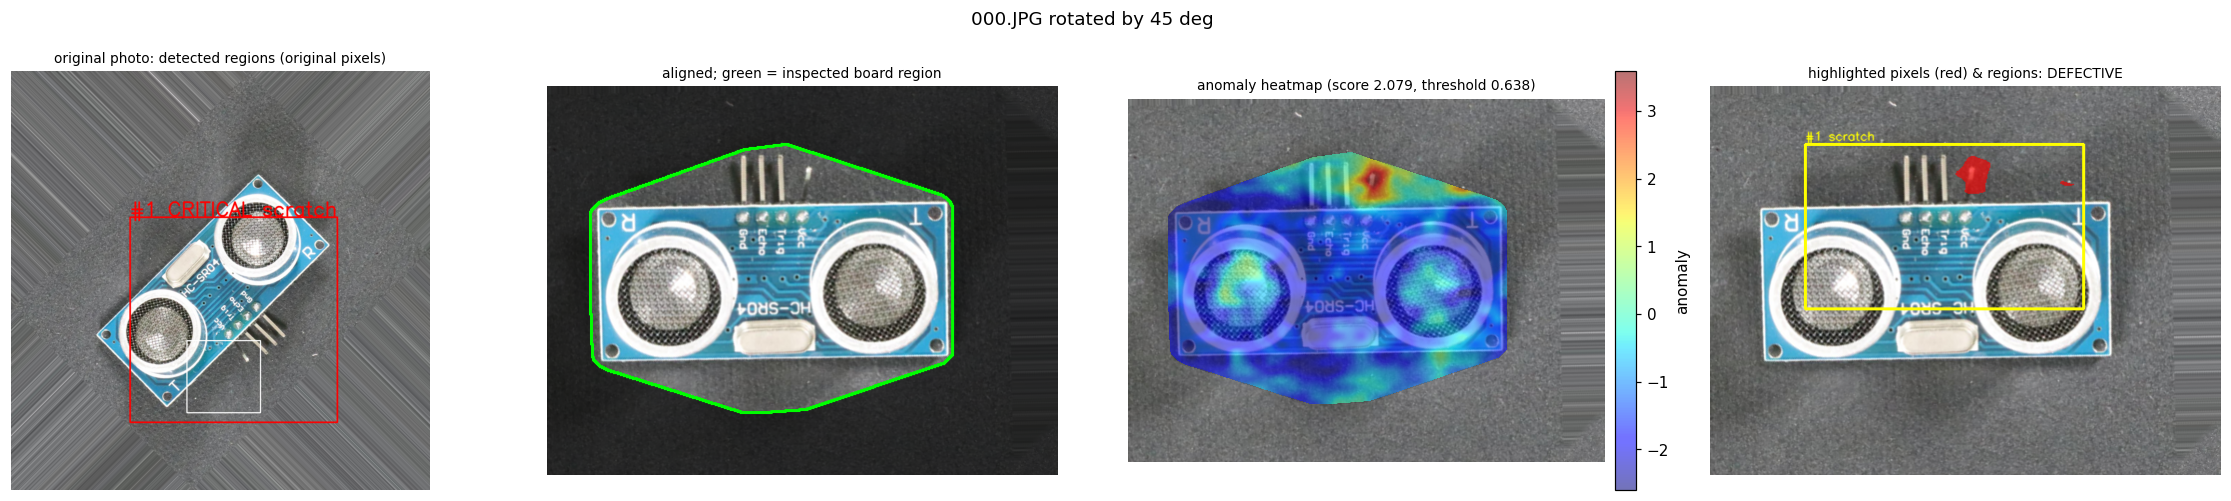

--------------------------------------------------------------------------------------------------------------
SYSTEM: Ours (canonical pipeline) | BOARD TYPE: pcb1 (keypoint inliers per class: {'pcb1': 95})
ALIGNMENT: OK | rotation undone -136.17 deg | scale 1.246 | 95 inliers | lighting corrected: False | retry: -
INSPECTED: 100.0% of the board (background surface ignored)
IMAGE SCORE: 2.0786 | empirical threshold 0.6378 -> DEFECTIVE | PAC threshold 0.8450 -> DEFECTIVE | ground truth: DEFECTIVE
DECISION: DEFECTIVE -- auto-reject (score above the strict PAC threshold)
MOST ANOMALOUS PIXEL: value 3.831 at original-photo pixel (977, 1196) (aligned (262, 87)) | highlighted pixels: 924 (pixel threshold 1.793)
 region priority                                                            defect-shape hint bbox in original photo (x0,y0,x1,y1) bbox highlighted in original photo (x0,y0,x1,y1) centre in original photo (x,y) peak pixel in original photo (x,y)  peak anomaly  mean anomaly  highlighte

In [7]:
# W7 -- fallback without Gradio: the same inspection, shown inline
from IPython.display import display
img, head, report = inspect_demo("PCB1", "bad", image_choices("PCB1", "bad")[0], 45)
print(head); display(img); print(report)